# Анализ TCR (TRB) для наивных CD8 T-клеток (nCD8)

Копия семинарского ноутбука `UCB_seminar.ipynb`, в которой анализ повторен на популяции nCD8 вместо nTreg.

## Imports

**Назначение библиотек.** `pandas` — таблицы и метаданные; `os`/`pathlib` — пути; `repseq.clonosets` — поиск таблиц клонотипов; `repseq.clone_filter` — фильтрация; `repseq.stats` — вычисление метрик; `repseq.plot` — построение графиков; `repseq.beta` — сравнение образцов; `repseq.clustering` — поиск близких последовательностей. `CategoricalDtype` задаёт порядок групп на графиках.

In [1]:
# Импортируем библиотеки, которые потребуются для таблиц, расчёта метрик и графиков.
import pandas as pd
from pandas.api.types import CategoricalDtype
import os

from repseq import clonosets as cl
from repseq import io as repseqio
from repseq import clone_filter as clf
from repseq import stats
from repseq import plot as rsplot
from repseq import clustering
from repseq import beta

**Относительные пути.** Ноутбук ищет корень проекта по наличию `environment.yml` и папки `notebooks`, поэтому не требует фиксированного домашнего каталога пользователя. Для корректной работы открывайте его из проекта или любой его вложенной папки. `WORKING_DIR` — место для **новых результатов**, а не для входных FASTQ/клоносетов.

## WORKING DIR

In [2]:
# Ищем корень проекта автоматически; затем задаём каталог для результатов repseq.
from pathlib import Path

# Portable to any unpacked ImmuneSem location.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").is_file() and (p / "notebooks").is_dir())
WORKING_DIR = str(PROJECT_ROOT / "outputs" / "repseq")


In [3]:
# Создаём outputs/repseq при первом запуске, если такой папки ещё нет.
os.makedirs(WORKING_DIR, exist_ok=True)

**Что представляет собой входной датасет.** Здесь используются уже обработанные данные RepSeq: файлы `*.clonotypes.TRB.txt` с клонотипами, а не исходные FASTQ. В исходной схеме подготовки данных MiGEC учитывал UMI, затем MiXCR собирал клонотипы. Поэтому счётчики с историческим названием *reads* в этих таблицах отражают результаты обработки на уровне молекулярных наблюдений, а не просто число исходных FASTQ-прочтений.

Обратите внимание на различие: **число клонотипов** — сколько различных последовательностей обнаружено; **число наблюдений** — сколько раз эти последовательности зарегистрированы. Именно второе используется при анализе частот и даунсэмплировании.

## Read clonosets

In [4]:
# Указываем папку с готовыми клоносетами и таблицей метаданных UCB.
clonosets_ucb_dir = str(PROJECT_ROOT / "data" / "ucb_figshare")


In [5]:
# Находим все клоносеты в каталоге и собираем таблицу ссылок на файлы;
# # show_offtarget=False исключает нерелевантные цепи по правилу библиотеки.
clonosets = cl.find_all_mixcr_clonosets(clonosets_ucb_dir, # <- put path (or a list of paths) to your folder(s) with clonosets
                                        show_offtarget=False, 
                                        offtarget_threshold=0.01
                                       )
clonosets

,sample_id,chain,filename
0,c4_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
1,UCB5_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
2,a12_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
3,o1_nTreg_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
4,o4_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
...,...,...,...
82,UCB1_nCD8_TRB_2,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
83,UCB6_nCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
84,o7_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
85,UCB9_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...


The dataset also contains metadata table, which can read as a pandas DataFrame

**Метаданные связывают образцы с экспериментом.** `sample_id` — имя образца и ключ объединения; `experimental_group` — возрастная/экспериментальная группа; `donor_id` — донор; `subset` — отсортированная клеточная популяция. Для групп `preterm`, `term`, `late` источник обозначается как UCB (пуповинная кровь), для остальных — PB (периферическая кровь).

Заданный порядок категорий нужен для осмысленного расположения групп на графиках; это **не** числовая переменная и **не** результат статистического теста. Проверяйте количество образцов в каждой группе, прежде чем сравнивать её с другими.

## Create metadata

In [6]:
# Задаём порядок экспериментальных групп и клеточных популяций для графиков.
# # Затем читаем метаданные и добавляем источник материала: UCB или PB.
# Define the custom ordered type
exp_group_order = CategoricalDtype(categories=['preterm', 'term', 'late', 'children', 'adults', 'older_adults'], ordered=True)
subset_order = CategoricalDtype(categories=["nCD4", "nTreg", "nCD8"], ordered=True)

metadata = pd.read_csv(os.path.join(clonosets_ucb_dir, "ucb_figshare_TRB_metadata.csv"))[["sample_id", "experimental_group", "donor_id", "subset"]]
metadata["experimental_group"] = metadata["experimental_group"].astype(exp_group_order)
metadata["subset"] = metadata["subset"].astype(subset_order)
metadata["source"] = metadata["experimental_group"].apply(lambda x: "UCB" if x in ['preterm', 'term', 'late'] else "PB")
# metadata["sample_id"] = metadata["sample_id"].apply(lambda x: x.split("_TRB")[0])
metadata.tail()

,sample_id,experimental_group,donor_id,subset,source
82,a6_nCD8_TRB_1,adults,a6,nCD8,PB
83,a4_nCD8_TRB_1,adults,a4,nCD8,PB
84,a12_nCD8_TRB_1,adults,a12,nCD8,PB
85,a14_nTreg_TRB_1,adults,a14,nTreg,PB
86,a16_nTreg_TRB_1,adults,a16,nTreg,PB


**Почему выделяем одну популяцию.** В датасете есть несколько отсортированных популяций (nCD4, nTreg, nCD8), их репертуары различаются и по биологии, и по глубине секвенирования. На семинаре анализировали `nTreg`, в этом ноутбуке **`nCD8`** (наивные CD8 T-клетки), чтобы сравнение возрастных групп не смешивалось с различиями клеточных типов.

## Subset clonosets

In [7]:
# Объединяем пути к клоносетам с метаданными и оставляем популяцию nCD8.
clonosets_cd8 = clonosets.merge(metadata).query("subset == 'nCD8'").reset_index(drop=True)
clonosets_cd8

,sample_id,chain,filename,experimental_group,donor_id,subset,source
0,c4_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,children,c4,nCD8,PB
1,UCB5_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,preterm,UCB5,nCD8,UCB
2,a12_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,adults,a12,nCD8,PB
3,o4_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,older_adults,o4,nCD8,PB
4,UCB13_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,term,UCB13,nCD8,UCB
5,a6_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,adults,a6,nCD8,PB
6,UCB2_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,term,UCB2,nCD8,UCB
7,o3_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,older_adults,o3,nCD8,PB
8,UCB4_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,late,UCB4,nCD8,UCB
9,c5_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,children,c5,nCD8,PB


In [8]:
# Сколько образцов nCD8 попало в каждую группу.
clonosets_cd8.groupby("experimental_group", observed=False).size().rename("samples").to_frame()

,samples
experimental_group,
preterm,3
term,6
late,4
children,4
adults,4
older_adults,6


In [9]:
# Проверяем схему сортировки образцов nCD8 по исходной таблице метаданных.
metadata_raw = pd.read_csv(os.path.join(clonosets_ucb_dir, "ucb_figshare_TRB_metadata.csv"))
metadata_raw.query("subset == 'nCD8'").groupby(["experimental_group", "sorting_subtype", "gating_strategy"]).size().rename("samples").to_frame()

samples
experimental_group sorting_subtype gating_strategy              
adults             nCD8            CD3+CD8+CD45RA+CD27+        4
children           nCD8            CD3+CD8+CD45RA+CD27+        4
late               nCD8            CD3+CD4-                    4
older_adults       nCD8            CD3+CD8+CD45RA+CD27+        6
preterm            nCD8            CD3+CD4-                    3
term               nCD8            CD3+CD4-                    4
                                   CD3+CD8+CD45RA+CD27+        2

**Сначала оценим объём и качество.** В `clonoset_stats` важно различать `clones` и `clones_func` (общее число клонотипов и продуктивных), `reads` и `reads_func` (число наблюдений), а также `clones_nonfunc` и синглтоны.

**Важное свойство конкретного набора:** в сохранённой таблице статистики колонки `umi`, `umi_func` и т. п. имеют значения `NaN`. Поэтому некоторые функции `repseq` выдают предупреждение и **используют `reads` вместо отдельного столбца UMI**. В этих исторически обработанных MiGEC/MiXCR-данных не следует автоматически отождествлять `reads` с сырыми ридами FASTQ. Это важно для объяснения `by_umi=True` ниже.

## Have a look at clonosets contents

In [10]:
# Для каждого образца рассчитываем число клонов, функциональных клонов и наблюдений.
clonoset_stats_cd8 = stats.calc_clonoset_stats(clonosets_cd8, cpu=2)
clonoset_stats_cd8

Using 2 cores
CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,c4_nCD8_TRB_1,TRB,37919,36571,26478,10093,1348,0.035549,53145,51597,1548,0.029128,NaN,NaN,NaN,NaN,NaN
1,UCB5_nCD8_TRB_1,TRB,48765,45777,20983,24794,2988,0.061273,106163,102609,3554,0.033477,NaN,NaN,NaN,NaN,NaN
2,a12_nCD8_TRB_1,TRB,20752,20166,19099,1067,586,0.028238,21981,21375,606,0.027569,NaN,NaN,NaN,NaN,NaN
3,o4_nCD8_TRB_1,TRB,5273,4931,2274,2657,342,0.064859,12971,12500,471,0.036312,NaN,NaN,NaN,NaN,NaN
4,UCB13_nCD8_TRB_1,TRB,42841,41255,32843,8412,1586,0.037021,55050,53362,1688,0.030663,NaN,NaN,NaN,NaN,NaN
5,a6_nCD8_TRB_1,TRB,19712,19070,17800,1270,642,0.032569,21232,20571,661,0.031132,NaN,NaN,NaN,NaN,NaN
6,UCB2_nCD8_TRB_1,TRB,81317,77851,41504,36347,3466,0.042623,146591,142640,3951,0.026953,NaN,NaN,NaN,NaN,NaN
7,o3_nCD8_TRB_1,TRB,5635,5332,3493,1839,303,0.053771,9313,8941,372,0.039944,NaN,NaN,NaN,NaN,NaN
8,UCB4_nCD8_TRB_1,TRB,15945,15199,8248,6951,746,0.046786,27886,27005,881,0.031593,NaN,NaN,NaN,NaN,NaN
9,c5_nCD8_TRB_1,TRB,35516,34463,27783,6680,1053,0.029649,44806,43652,1154,0.025755,NaN,NaN,NaN,NaN,NaN


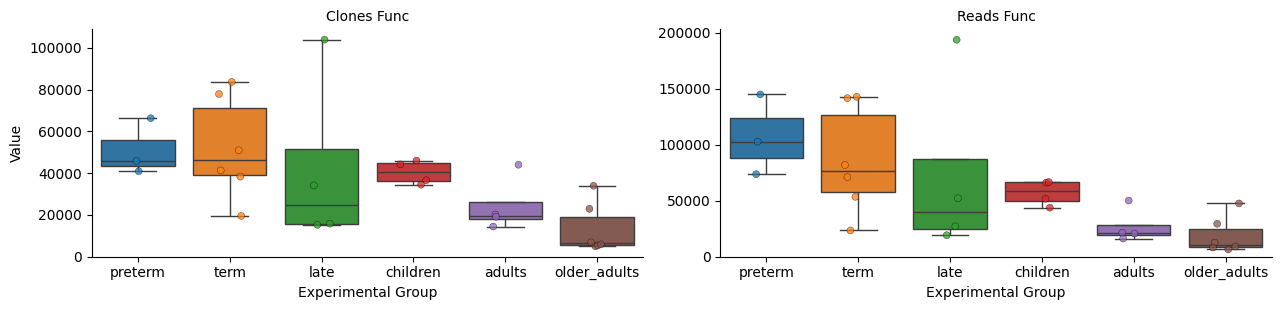

In [11]:
# Сравниваем объём функциональной части репертуаров между экспериментальными группами.
rsplot.clonoset_stats(clonoset_stats_cd8, metadata=metadata, group="experimental_group", properties=["clones_func", "reads_func"], aspect=2)

In [12]:
# Сортируем образцы по числу функциональных наблюдений: это помогает выбрать downsample.
clonoset_stats_cd8.sort_values(by="reads_func")

,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
25,o7_nCD8_TRB_1,TRB,5972,5823,5515,308,149,0.024950,6522,6368,154,0.023612,NaN,NaN,NaN,NaN,NaN
10,o2_nCD8_TRB_1,TRB,7077,6818,6027,791,259,0.036597,8325,8056,269,0.032312,NaN,NaN,NaN,NaN,NaN
7,o3_nCD8_TRB_1,TRB,5635,5332,3493,1839,303,0.053771,9313,8941,372,0.039944,NaN,NaN,NaN,NaN,NaN
3,o4_nCD8_TRB_1,TRB,5273,4931,2274,2657,342,0.064859,12971,12500,471,0.036312,NaN,NaN,NaN,NaN,NaN
21,a5_nCD8_TRB_1,TRB,15111,14377,12881,1496,734,0.048574,16879,16091,788,0.046685,NaN,NaN,NaN,NaN,NaN
20,UCB7_nCD8_TRB_1,TRB,16440,15764,13016,2748,676,0.041119,19808,19100,708,0.035743,NaN,NaN,NaN,NaN,NaN
5,a6_nCD8_TRB_1,TRB,19712,19070,17800,1270,642,0.032569,21232,20571,661,0.031132,NaN,NaN,NaN,NaN,NaN
2,a12_nCD8_TRB_1,TRB,20752,20166,19099,1067,586,0.028238,21981,21375,606,0.027569,NaN,NaN,NaN,NaN,NaN
12,UCB12_nCD8_TRB_1,TRB,20368,19465,16504,2961,903,0.044334,24244,23304,940,0.038772,NaN,NaN,NaN,NaN,NaN
8,UCB4_nCD8_TRB_1,TRB,15945,15199,8248,6951,746,0.046786,27886,27005,881,0.031593,NaN,NaN,NaN,NaN,NaN


In [13]:
# Сводка по глубине: минимум, медиана и максимум по группам.
depth_summary = clonoset_stats_cd8.merge(metadata, on="sample_id")
print("Функциональных наблюдений: от", depth_summary["reads_func"].min(), "до", depth_summary["reads_func"].max())
depth_summary.groupby("experimental_group", observed=True)[["clones_func", "reads_func"]].agg(["min", "median", "max"])

Функциональных наблюдений: от 6368 до 193529


clones_func                  reads_func                  
                           min   median     max        min    median     max
experimental_group                                                          
preterm                  40913  45777.0   66274      73563  102609.0  144769
term                     19465  46082.0   83632      23304   76396.0  142640
late                     15199  24929.0  103879      19100   39571.0  193529
children                 34463  40365.5   45987      43652   58813.5   66536
adults                   14377  19618.0   43989      16091   20973.0   50019
older_adults              4931   6320.5   33909       6368   10720.5   47469

In [14]:
# Выбор глубины даунсэмплинга для nCD8 (обоснование ниже).
DOWNSAMPLE = 6300   # чуть меньше самого маленького образца (o7_nCD8_TRB_1, 6368), сохраняет все образцы

# Для проверки устойчивости берем глубину, при которой выпадает только самый маленький образец:
# второй по размеру образец, округленный вниз до тысяч.
depths = clonoset_stats_cd8.sort_values("reads_func")[["sample_id", "reads_func"]].reset_index(drop=True)
DOWNSAMPLE_CHECK = int(depths.loc[1, "reads_func"] // 1000 * 1000)

func_filter = clf.Filter(functionality="f", by_umi=True)
downsample_filter = clf.Filter(functionality="f", downsample=DOWNSAMPLE, by_umi=True, seed=100)

print("Самые маленькие образцы:")
display(depths.head(4).merge(metadata[["sample_id", "experimental_group"]], on="sample_id"))
for d in [DOWNSAMPLE, DOWNSAMPLE_CHECK]:
    small = clonoset_stats_cd8.query("reads_func < @d")["sample_id"].tolist()
    print(f"downsample={d}: образцов меньше этой глубины - {len(small)} {small}")

Самые маленькие образцы:


,sample_id,reads_func,experimental_group
0,o7_nCD8_TRB_1,6368,older_adults
1,o2_nCD8_TRB_1,8056,older_adults
2,o3_nCD8_TRB_1,8941,older_adults
3,o4_nCD8_TRB_1,12500,older_adults


downsample=6300: образцов меньше этой глубины - 0 []
downsample=8000: образцов меньше этой глубины - 1 ['o7_nCD8_TRB_1']


**Почему downsample = 6300.** Глубина функциональной части у образцов nCD8 сильно различается (точный диапазон в сводке выше). Даунсэмплинг должен быть не больше самого маленького образца, иначе тот выпадет. Самый маленький образец это `o7_nCD8_TRB_1` (older_adults, 6368 наблюдений), поэтому берем 6300: все образцы сохраняются, в том числе o7. Это важно, потому что older_adults и так маленькая группа.

Для проверки устойчивости (`DOWNSAMPLE_CHECK`) берем глубину второго по размеру образца, округленную вниз до тысяч. Тогда выпадает только o7, а глубина становится больше. В конце ноутбука сравниваем результаты при двух глубинах.

`by_umi=True` оставлен как на семинаре, колонки UMI в этих данных пустые, поэтому repseq использует `reads`.

**Один фильтр — одинаковые правила для всех образцов.** `clf.Filter` хранит настройки, которые передаются в вычислительные функции. Фильтры нужны, чтобы исключать нефункциональные последовательности, ограничивать число клонотипов или выравнивать число наблюдений между образцами.

- `functionality='f'` оставляет продуктивные последовательности (в рамке считывания, без стоп-кодона в соответствующем участке). Непродуктивные транскрипты могут реже наблюдаться из-за отбора и, в части случаев, NMD; их доля в данных **не** обязана быть равна доле непроизводительных перестроек на уровне ДНК.
- `top` оставляет наиболее многочисленные клонотипы; `downsample` выбирает заданное **число наблюдений** случайным образом. Это разные процедуры: первая обогащает частые клоны, вторая стандартизирует глубину.
- `seed` фиксирует случайность и делает сравнение воспроизводимым. `by_umi=True` предпочтителен при наличии UMI-счётчиков; когда отдельного поля нет, проверяйте сообщения библиотеки о фактически выбранном счётчике.

Почему нельзя напрямую сравнить число обнаруженных клонотипов в образцах с существенно разной глубиной?

Потому что число найденных клонотипов сильно зависит от того, сколько наблюдений прочитали: чем глубже образец, тем больше редких клонотипов в нем находится. В наших данных у самого маленького образца o7_nCD8_TRB_1 (6368 наблюдений) 5823 функциональных клонотипа, а у самого большого UCB9_nCD8_TRB_1 (193529 наблюдений) 103879, разница почти в 18 раз. После даунсэмплинга до 6300 у них 5764 и 6132 клонотипа, разница всего около 6%. Без выравнивания глубины мы бы сравнивали глубину секвенирования, а не биологию.

## Filters

**`Filter` - is a special object, that may be used as a setup for Postanalysis.** You can easily create or change one and put it as an argument to other functions for individual clonoset or multi-clonoset metrics

Here is a basic default filter with all possible options:

In [15]:
# Просматриваем все настройки объекта Filter. Это пример конфигурации, не запуск анализа.
clf.Filter(name="default_filter",         # <- name of the filter
           functionality="a",             # <- functional clonotypes = clonotypes without STOP codons or out-of-frames (OOFs) in the CDR3 region, "a" = all clonotypes, "f" = leave only functional, "n" = leave only non-functional
           downsample=None,               # <- randomly downsample to this count value
           top=None,                      # <- take top-N clonotypes
           by_umi=False,                  # <- False = count by read-counts, True = count by UMI counts, if such a column exists
           mix_tails=False,               # <- True = mix all clonotypes with same counts randomly
           count_threshold=None,          # <- set minimal count value for clonotypes, others will be filtered out
           unweight=False,                # <- set count=1 to all clonotypes
           seed=None,                     # <- set seed for random processes, like downsampling and mixing tails for reproducibility
           recount_fractions=True,        # <- should you normalize all fractions to sum to 1 after filtering procedures?
           white_list=[],                 # <- a list of clonotypes, that should be left in the clonoset (the syntax for the list is below)
           black_list=[],                 # <- a list of clonotypes, that should be filtered out
           pool_clonoset_by="",           # <- combine clonotypes into one by CDR3, V or J equlity
           convert=True,                  # <- convert=False preserves all the columns of the original clonoset table. Otherwise the clonoset will be converted into VDJtools-like format for simplicity
           ignore_small_clonosets=False   # <- =True suppreses the warnings when clonoset is smaller than the given downsample or top values.
          )

Here are some examples of useful filters:

### Functional

functionality options: `a` (default) - any. `f` - only functional, `n` - only non-functional

In [16]:
# Оставляем функциональные клонотипы и используем счётчики UMI, если они доступны.
func_filter = clf.Filter(functionality="f", by_umi=True)
func_filter

**`top=4000` не означает 4000 наблюдений.** Это выбор 4000 клонотипов с наибольшими счётчиками. Если несколько клонотипов имеют одинаковый счётчик около границы отсечения, `mix_tails=True` перемешивает их для уменьшения зависимости результата от порядка строк. `seed=100` делает такое перемешивание повторяемым.

### Top

top clonotypes by count. Recommended to mix the tails and specify the seed

In [17]:
# Сохраняем 4000 наиболее частых клонов; смешиваем равные по счётчику хвосты случайно.
top_filter = clf.Filter(functionality="f", top=4000, by_umi=True, mix_tails=True, seed=100)
top_filter

**Зачем нужен даунсэмпл.** Сравнение разнообразия без контроля глубины может дать ложное преимущество глубоко прочитанному образцу: чем больше наблюдений, тем больше редких клонотипов можно обнаружить. `downsample=4500` задаёт общую глубину для примера с nTreg, но **не является универсальным порогом** для остальных клеточных популяций. Его выбирают после изучения распределения размеров образцов; слишком высокий порог может привести к исключению малых образцов.

### Downsample

Take a random sample by counts (UMI or reads). Seed is recommended to use for reproducibility.

Usually used for Diversity metrics, Convergence and other procedures, which require sample normalization

In [18]:
# Приводим образцы к одинаковой глубине DOWNSAMPLE (6300) с фиксированным seed.
downsample_filter = clf.Filter(functionality="f", downsample=DOWNSAMPLE, by_umi=True, seed=100)
downsample_filter

# Analysis

**Свойства CDR3.** CDR3 — наиболее вариабельная область рецептора, в формировании которой участвуют V(D)J-рекомбинация, обрезание концов и вставки нуклеотидов. Помимо длины можно описывать физико-химические свойства аминокислотной последовательности (заряд, гидрофобность и др.). Графики ниже сравнивают распределения **по образцам**, сгруппированным по `experimental_group`; отдельные точки — это не независимые T-клетки.

Найденное различие не обязательно означает различие антигенной специфичности: это косвенные характеристики репертуара.

## CDR3 properties

Calculates different properties for CDR3 region. In this case we passed `func_filter` to make calculations only for 'functional' clonotypes

In [19]:
# Считаем длину, вставки и свойства аминокислот CDR3 для функциональных клонов.
cdr3_properties = stats.calc_cdr3_properties(clonosets_cd8, cl_filter=func_filter, cpu=2)
cdr3_properties

Using 2 cores
CalcCDR3aaProperties |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,mean_cdr3nt_len,mean_insert_size,zero_insert_freq,mean_frequency,cdr3_5_hydropathy,cdr3_full_hydropathy,cdr3_5_charge,cdr3_full_charge,...,cdr3_5_turn,cdr3_full_turn,cdr3_5_alpha,cdr3_full_alpha,cdr3_5_beta,cdr3_full_beta,cdr3_5_core,cdr3_full_core,cdr3_5_disorder,cdr3_full_disorder
0,c4_nCD8_TRB_1,TRB,43.241642,7.000698,0.025467,0.000027,-3.636442,-4.126164,-0.097234,-0.746749,...,5.907985,15.041872,4.485906,14.275806,4.801015,14.065160,0.288009,0.775499,2.356183,2.879315
1,UCB5_nCD8_TRB_1,TRB,40.542262,2.925835,0.297216,0.000022,-4.575597,-3.703759,-0.090937,-0.552154,...,5.869985,14.020471,4.505857,13.375733,4.819886,13.244480,0.293199,0.728685,2.276067,2.271955
2,a12_nCD8_TRB_1,TRB,43.383860,7.379135,0.021895,0.000050,-3.858484,-4.227920,-0.082760,-0.683135,...,5.889649,15.061593,4.494039,14.320047,4.801775,14.123816,0.287871,0.776815,2.370667,2.778058
3,o4_nCD8_TRB_1,TRB,43.345440,7.112000,0.025520,0.000203,-3.701512,-3.804624,0.075200,-0.489360,...,5.782857,14.944432,4.499513,14.259789,4.866736,14.214689,0.287841,0.777616,2.104160,2.466080
4,UCB13_nCD8_TRB_1,TRB,42.122559,5.696076,0.086504,0.000024,-3.668463,-3.464806,-0.070706,-0.653986,...,5.867639,14.560540,4.505142,13.948072,4.812484,13.717956,0.290146,0.754900,2.276620,2.594243
5,a6_nCD8_TRB_1,TRB,43.272277,7.352341,0.023528,0.000052,-3.341597,-3.769263,-0.134413,-0.749891,...,5.860428,15.005218,4.507167,14.310524,4.823279,14.090764,0.287840,0.775569,2.223227,2.656118
6,UCB2_nCD8_TRB_1,TRB,42.529711,5.970738,0.067127,0.000013,-3.635107,-3.096446,-0.146579,-0.683013,...,5.886711,14.776530,4.499401,13.997487,4.809530,13.882475,0.288979,0.763118,2.256422,2.530244
7,o3_nCD8_TRB_1,TRB,43.963203,7.795325,0.013869,0.000188,-4.100179,-4.553506,0.015994,-0.482161,...,5.872966,15.260246,4.476300,14.464089,4.814015,14.335421,0.287575,0.788507,2.315625,2.700593
8,UCB4_nCD8_TRB_1,TRB,42.294834,5.994483,0.061248,0.000066,-3.550628,-3.677452,-0.085021,-0.707684,...,5.884632,14.665745,4.494832,13.960893,4.812020,13.791584,0.289566,0.759499,2.267506,2.531124
9,c5_nCD8_TRB_1,TRB,42.744296,6.925158,0.026872,0.000029,-4.014302,-3.617472,-0.059677,-0.557042,...,5.904939,14.877178,4.486514,14.064015,4.791427,13.911549,0.288422,0.765138,2.427380,2.725190


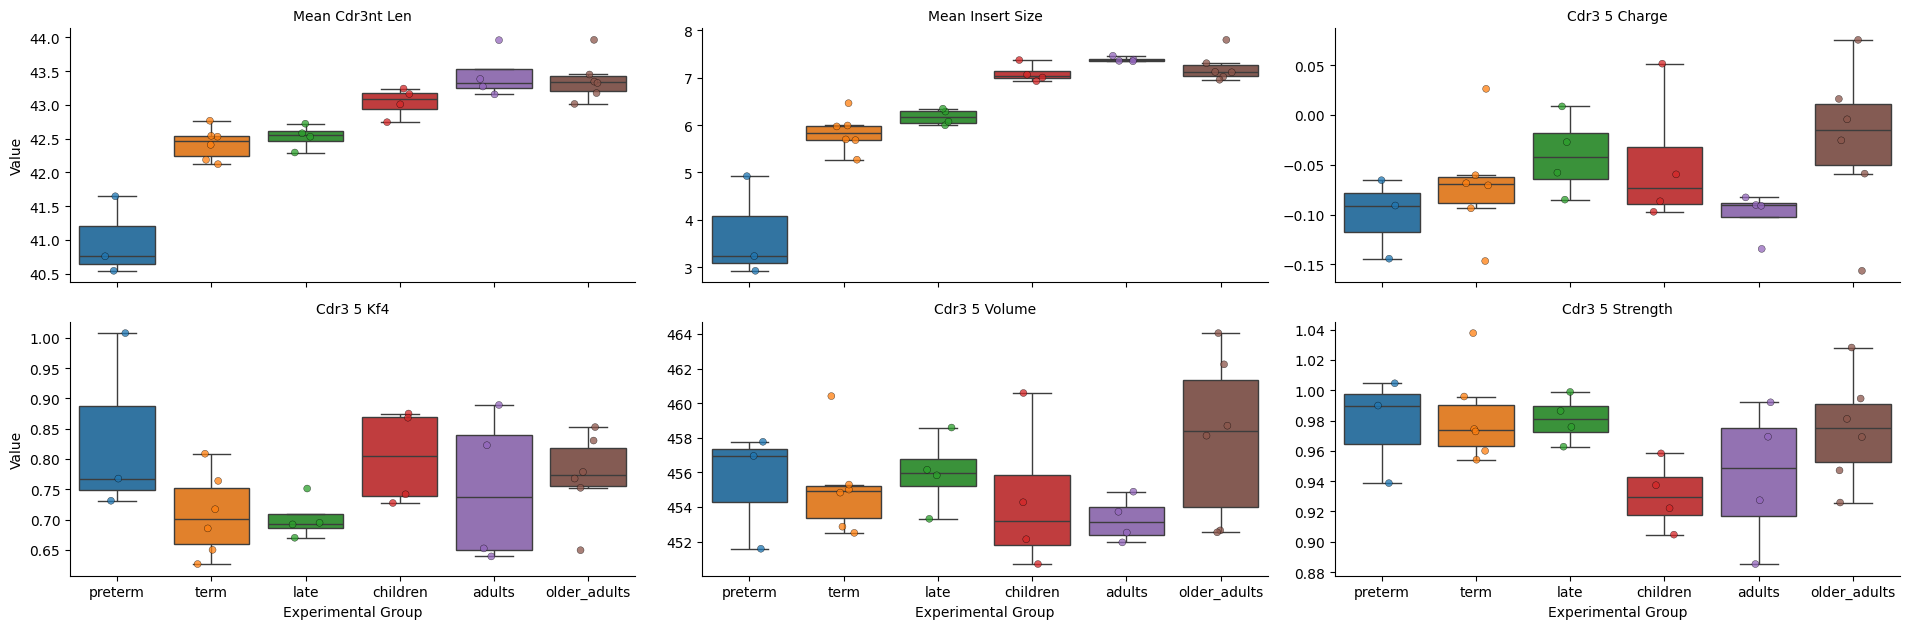

In [20]:
# Отображаем свойства CDR3 по экспериментальным группам, один образец — одно наблюдение.
rsplot.cdr3aa_stats(cdr3_properties,
                     metadata=metadata,
                     properties=None,
                     group="experimental_group",
                     split=None,
                     palette=None,
                     height=3.2,
                     aspect=2,
                    )

In [21]:
# Медианы по группам: длина CDR3 (нт), средний размер вставок и доля CDR3 без вставок.
cdr3_properties.merge(metadata, on="sample_id").groupby(
    "experimental_group", observed=True)[["mean_cdr3nt_len", "mean_insert_size", "zero_insert_freq"]].median().round(3)

,mean_cdr3nt_len,mean_insert_size,zero_insert_freq
experimental_group,,,
preterm,40.758,3.237,0.268
term,42.469,5.833,0.074
late,42.555,6.177,0.058
children,43.085,7.031,0.024
adults,43.328,7.366,0.023
older_adults,43.335,7.116,0.025


In [22]:
# Записываем рассчитанные свойства CDR3 в CSV для повторного использования.
cdr3_properties.to_csv(os.path.join(WORKING_DIR, "cdr3_properties.csv"), index=False)

**Распределение длин CDR3.** Здесь сравниваются `preterm` (недоношенные) и `late` (поздний срок гестации) **в одной клеточной популяции**. `seq_type='aa'` задаёт длину в аминокислотах, а `count_by_freq=True` — относительные частоты, а не абсолютное число последовательностей. Ненулевые вставки при рекомбинации могут увеличивать длину CDR3; биологическая гипотеза о возрастном различии связана в том числе с активностью TdT.

На первом графике смотрим профили отдельных образцов, на втором — их группировку. 

Сдвиг распределения отражает изменение средней длины, формы распределения или обоих параметров?

Обоих, но в основном сдвигается среднее. Средняя длина CDR3 у preterm меньше примерно на 1,8 нт (40,8 против 42,6 нт у late), это около 0,6 аминокислоты. Форма похожая, одна вершина около 13-15 аминокислот, но у preterm больше коротких CDR3 (11-13 аминокислот около 45% против 33% у late) и меньше длинных (16-18 аминокислот около 11% против 20%), то есть правый хвост у preterm тоньше. Это сходится с тем, что у preterm меньше вставок. При этом в группах всего 3 и 4 образца.

## CDR3len distributions

In [23]:
# Выбираем nCD8 из групп preterm и late для сравнения сроков гестации.
preterm_late_cd8 = clonosets_cd8.query("experimental_group in ['preterm', 'late']")
preterm_late_cd8

,sample_id,chain,filename,experimental_group,donor_id,subset,source
1,UCB5_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,preterm,UCB5,nCD8,UCB
8,UCB4_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,late,UCB4,nCD8,UCB
16,UCB11_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,preterm,UCB11,nCD8,UCB
18,UCB8_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,late,UCB8,nCD8,UCB
20,UCB7_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,late,UCB7,nCD8,UCB
24,UCB1_nCD8_TRB_2,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,preterm,UCB1,nCD8,UCB
26,UCB9_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,late,UCB9,nCD8,UCB


In [24]:
# Получаем частотное распределение длины CDR3 в аминокислотах для каждого образца.
# # zero_fill=True оставляет нулевые частоты для отсутствующих в образце длин.
cdr3_len_distribs = stats.cdr3_length_distributions(
                                                        preterm_late_cd8,
                                                        cl_filter=func_filter,
                                                        cpu=None,
                                                        count_by_freq=True,
                                                        seq_type="aa",
                                                        table="long",
                                                        zero_fill=True,
                                                        verbose=True,
                                                        drop_small_samples=False,
                                                    )
cdr3_len_distribs

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcCDR3LengthDistribution |##################################################| 7/7 calcultaion(s) processed


,sample_id,chain,cdr3_length,freq
0,UCB11_nCD8_TRB_1,TRB,4,0.000014
1,UCB11_nCD8_TRB_1,TRB,5,0.000041
2,UCB11_nCD8_TRB_1,TRB,6,0.000035
3,UCB11_nCD8_TRB_1,TRB,7,0.000104
4,UCB11_nCD8_TRB_1,TRB,8,0.000801
...,...,...,...,...
163,UCB9_nCD8_TRB_1,TRB,23,0.000041
164,UCB9_nCD8_TRB_1,TRB,24,0.000016
165,UCB9_nCD8_TRB_1,TRB,26,0.000005
166,UCB9_nCD8_TRB_1,TRB,27,0.000005


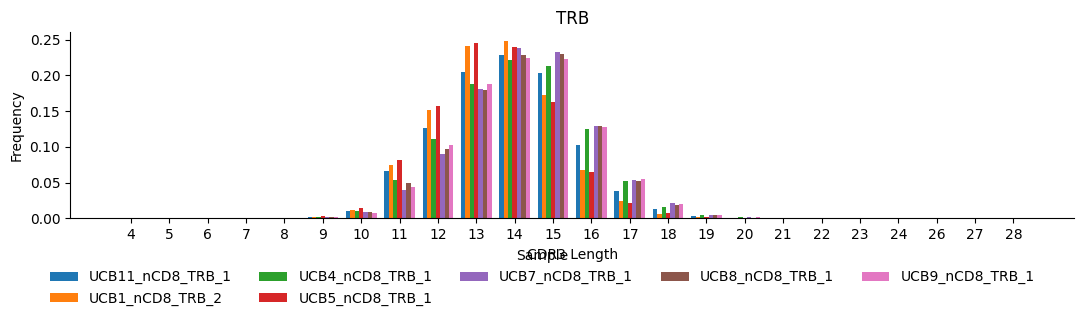

In [25]:
# Показываем распределения длин для отдельных образцов без разбиения по группам.
rsplot.cdr3_length_distributions(cdr3_len_distribs)

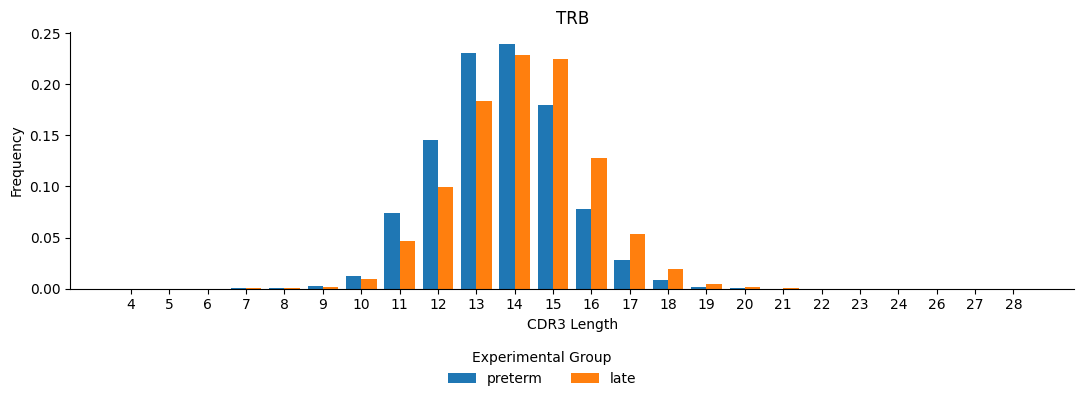

In [26]:
# Показываем те же распределения, добавляя возрастные/экспериментальные группы.
rsplot.cdr3_length_distributions(cdr3_len_distribs, metadata=metadata, group="experimental_group", height=4)

**Использование сегментов (segment usage).** При сборке TCR используются разные V- и J-сегменты. Их частоты не обязаны быть одинаковыми: влияют особенности рекомбинации, отбора и экспансии клонотипов. Это **описательная метрика**; высокое использование одного сегмента само по себе не доказывает ответ на определённый антиген.

`v_usage`/`j_usage` — таблицы относительного использования сегментов по образцам; тепловая карта, boxplot и barplot показывают одни данные разными способами. `combine_families=True` объединяет родственные V-гены по семействам, поэтому детализация становится грубее.

## Segment usage

### V-usage

In [27]:
# Считаем частоту использования каждого V-сегмента в каждом функциональном репертуаре.
v_usage = stats.calc_segment_usage(clonosets_cd8, segment="v", cl_filter=func_filter, table="long")
v_usage

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,v,usage
0,c4_nCD8_TRB_1,TRB,TRBV1,0.000155
1,UCB5_nCD8_TRB_1,TRB,TRBV1,0.000390
2,a12_nCD8_TRB_1,TRB,TRBV1,0.000047
3,o4_nCD8_TRB_1,TRB,TRBV1,0.000560
4,UCB13_nCD8_TRB_1,TRB,TRBV1,0.000169
...,...,...,...,...
1669,UCB10_nCD8_TRB_1,TRB,TRBV5-2,0.000000
1670,UCB6_nCD8_TRB_1,TRB,TRBV5-2,0.000000
1671,UCB1_nCD8_TRB_2,TRB,TRBV5-2,0.000000
1672,o7_nCD8_TRB_1,TRB,TRBV5-2,0.000000


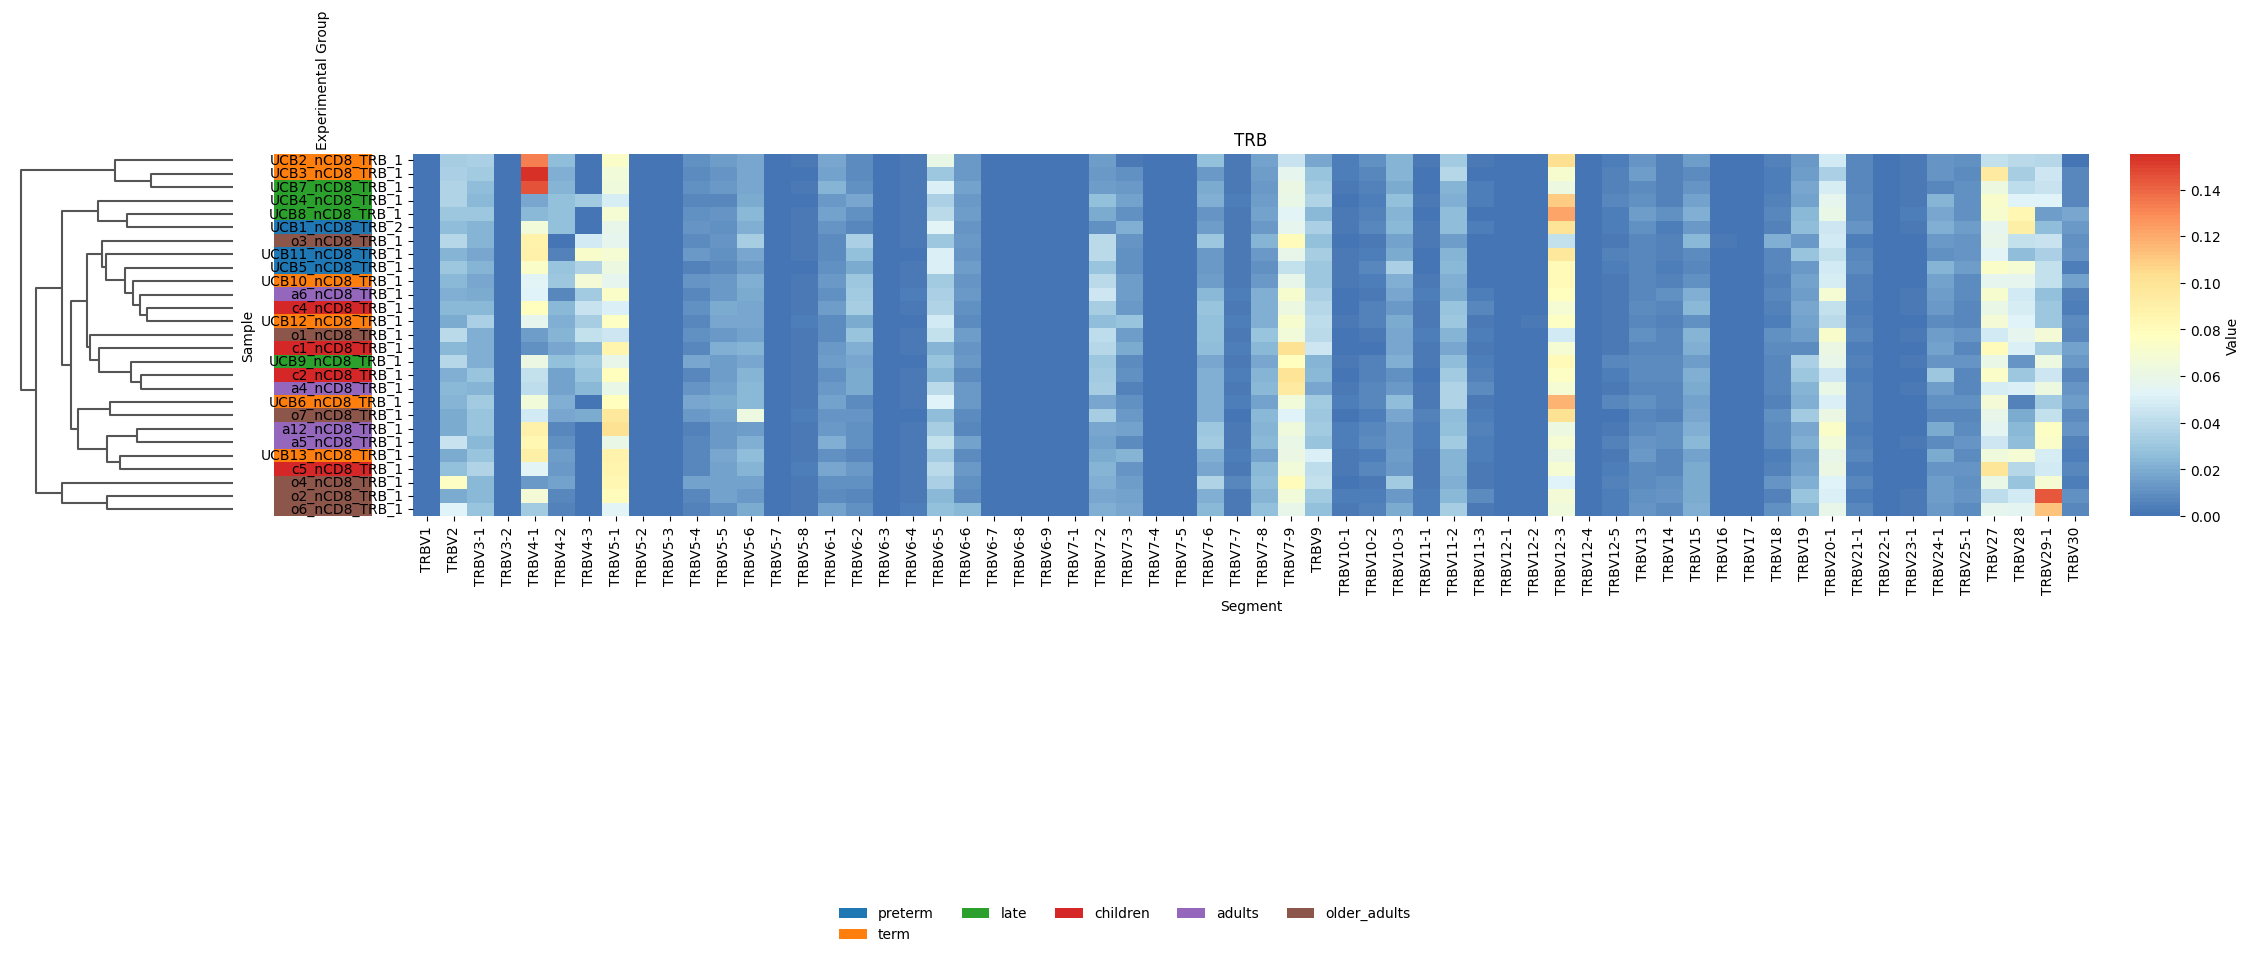

In [28]:
# Тепловая карта: образцы или группы сопоставляются по профилям использования V.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="heatmap", height=7)

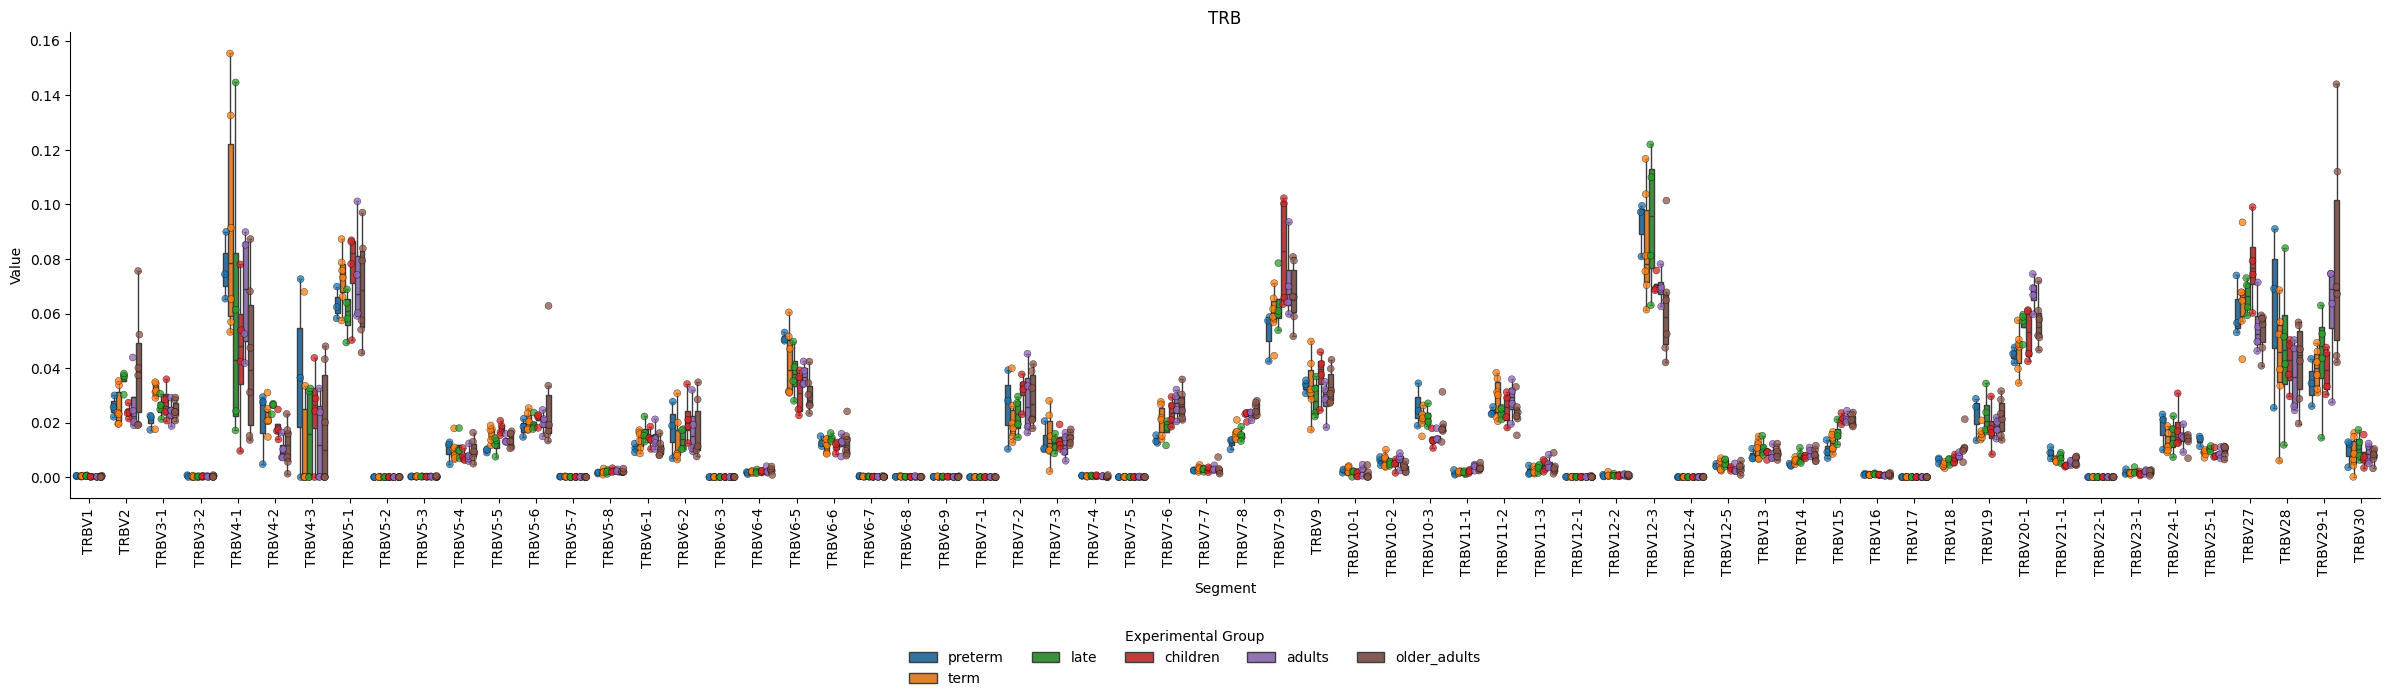

In [29]:
# Boxplot показывает вариацию использования V-сегментов между образцами групп.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, )

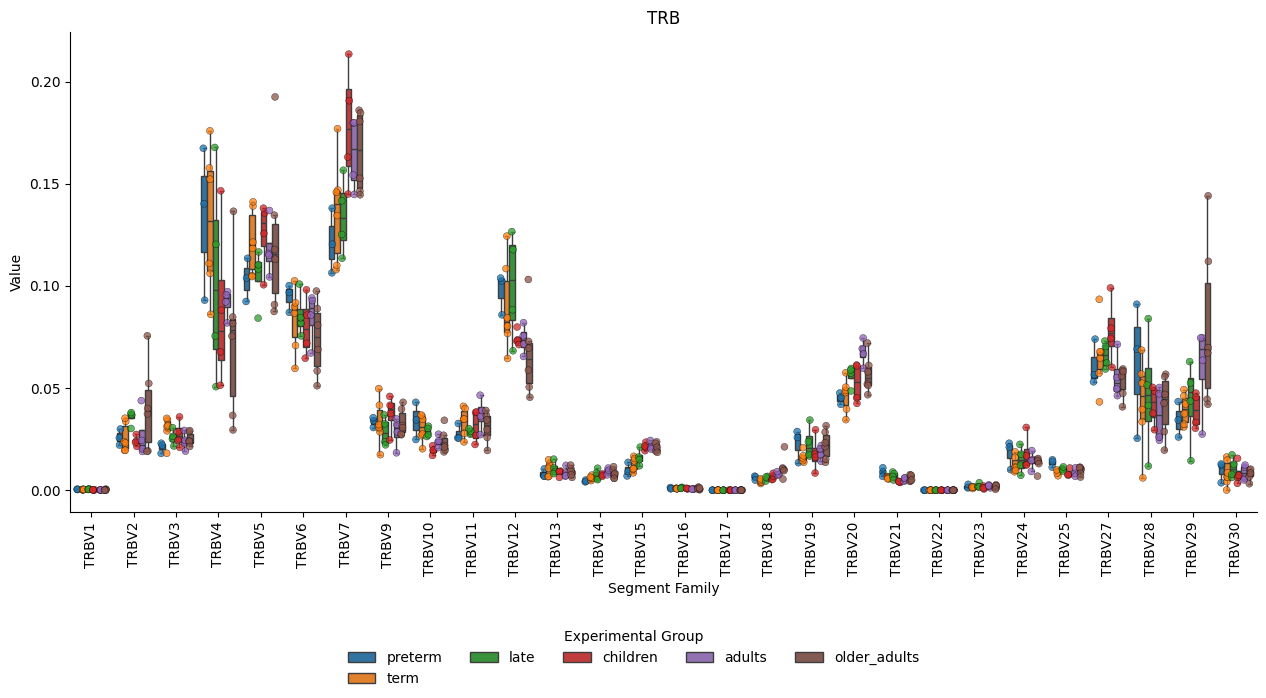

In [30]:
# Объединяем V-гены по семействам, чтобы увидеть более крупные закономерности.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, combine_families=True)

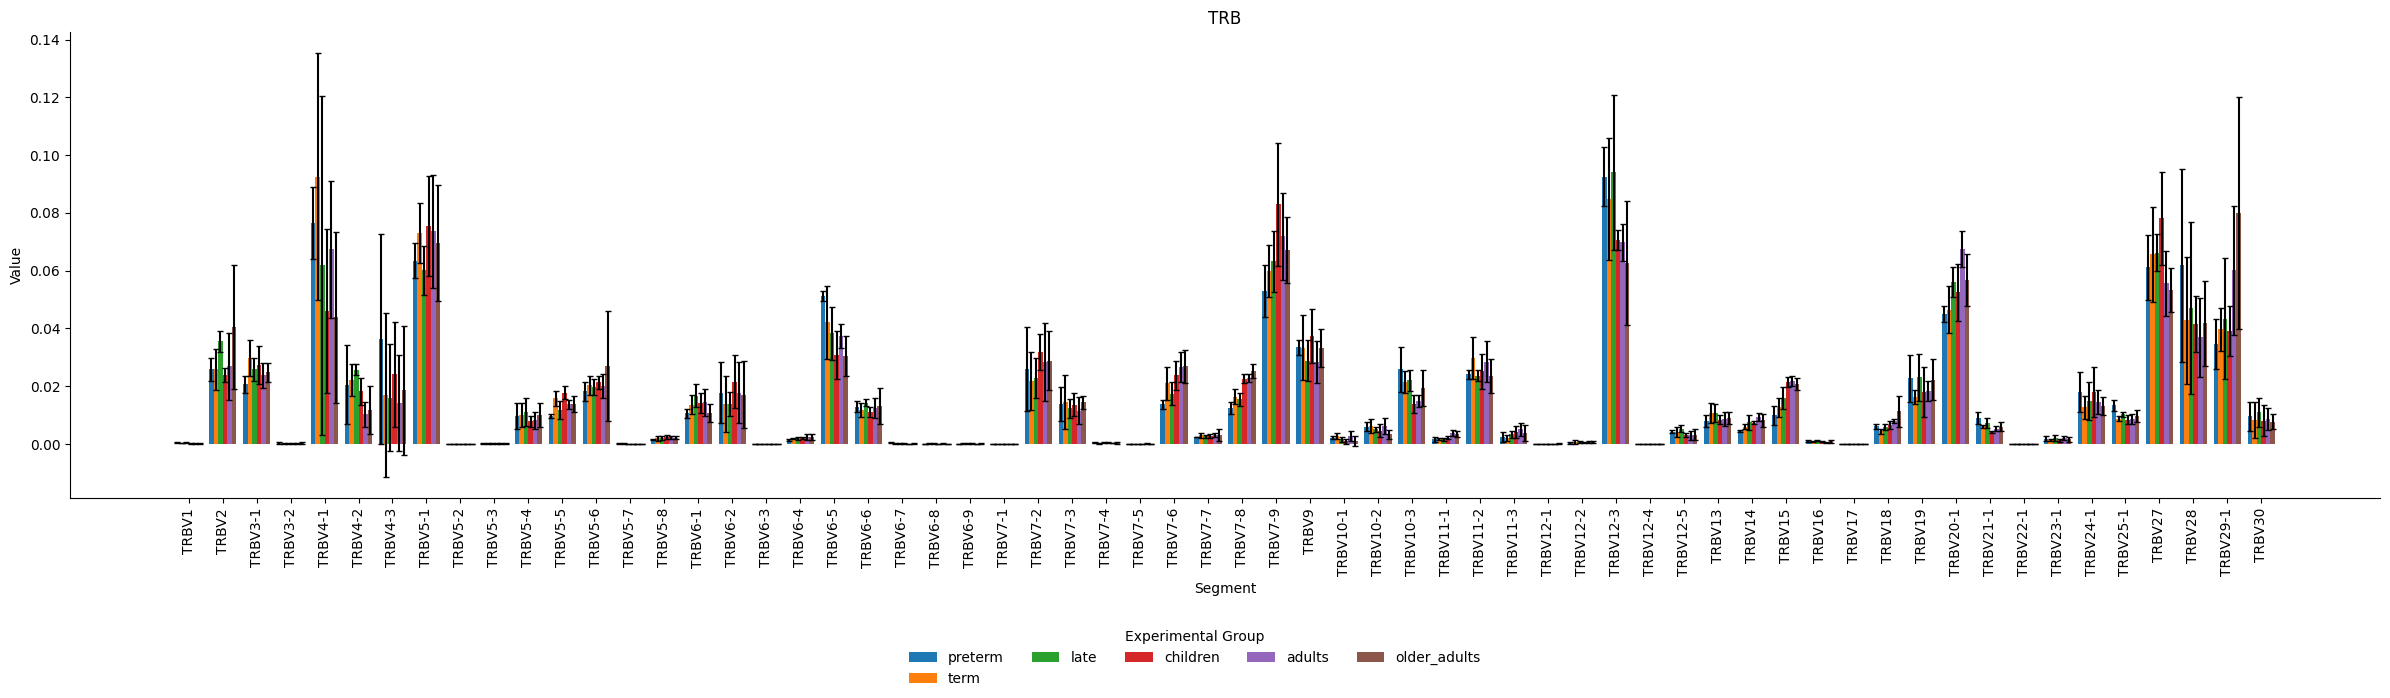

In [31]:
# Barplot показывает частоты отдельных V-генов.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

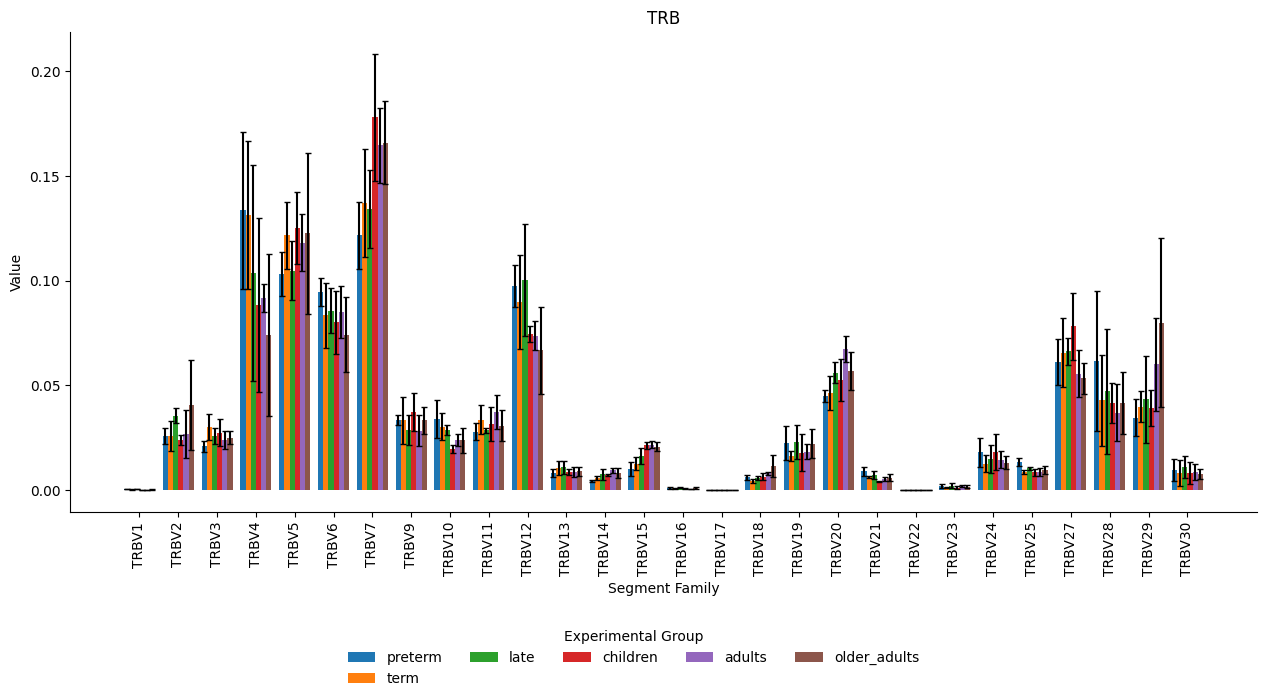

In [32]:
# Barplot для частот V-семейств вместо отдельных V-генов.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7, combine_families=True)

### J-usage

In [33]:
# Считаем частоты использования J-сегментов вместо V-сегментов.
j_usage = stats.calc_segment_usage(clonosets_cd8, segment="j", cl_filter=func_filter)
j_usage

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,j,usage
0,c4_nCD8_TRB_1,TRB,TRBJ1-1,0.065372
1,UCB5_nCD8_TRB_1,TRB,TRBJ1-1,0.115584
2,a12_nCD8_TRB_1,TRB,TRBJ1-1,0.111392
3,o4_nCD8_TRB_1,TRB,TRBJ1-1,0.075840
4,UCB13_nCD8_TRB_1,TRB,TRBJ1-1,0.076421
...,...,...,...,...
346,UCB10_nCD8_TRB_1,TRB,TRBJ2-7,0.207796
347,UCB6_nCD8_TRB_1,TRB,TRBJ2-7,0.214425
348,UCB1_nCD8_TRB_2,TRB,TRBJ2-7,0.249650
349,o7_nCD8_TRB_1,TRB,TRBJ2-7,0.209799


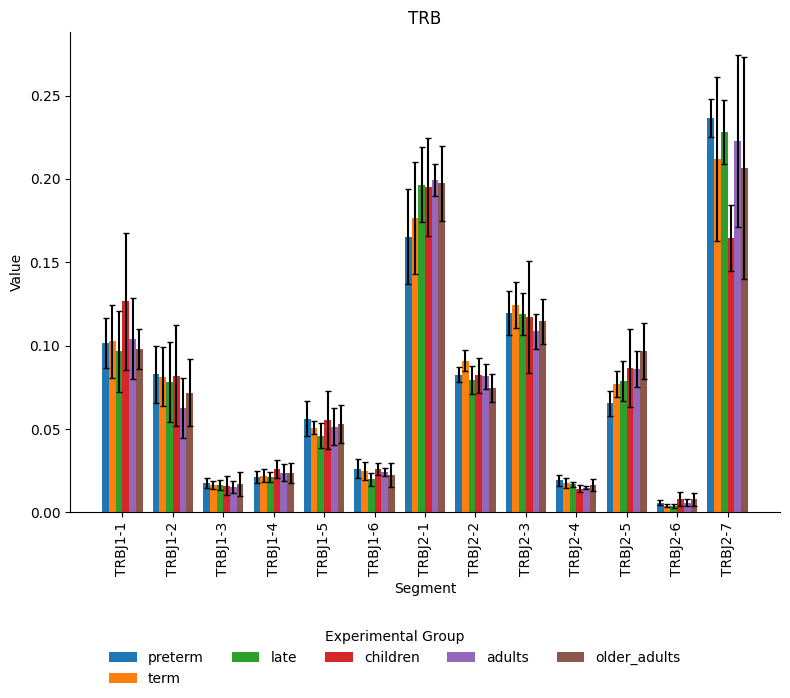

In [34]:
# Отображаем J-usage по экспериментальным группам.
rsplot.segment_usage(j_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

In [35]:
# Медиана доли каждого сегмента по образцам группы; показываем самые частые V и все J.
def usage_summary(usage, segment, top=None):
    d = usage.merge(metadata, on="sample_id")
    table = d.groupby([segment, "experimental_group"], observed=True)["usage"].median().unstack()
    table["all_samples"] = d.groupby(segment)["usage"].median()
    table = table.sort_values("all_samples", ascending=False)
    return (100 * (table.head(top) if top else table)).round(1)

print("V-сегменты, медиана доли, %")
display(usage_summary(v_usage, "v", top=8))
print("J-сегменты, медиана доли, %")
display(usage_summary(j_usage, "j"))

V-сегменты, медиана доли, %


experimental_group,preterm,term,late,children,adults,older_adults,all_samples
v,,,,,,,
TRBV12-3,9.7,7.8,9.6,6.9,6.9,5.9,7.0
TRBV5-1,6.2,7.4,6.1,8.2,6.7,6.8,6.9
TRBV7-9,5.7,6.0,6.0,8.3,6.7,6.6,6.3
TRBV4-1,7.4,7.8,4.3,4.8,6.9,3.9,6.1
TRBV27,5.7,6.6,6.6,7.7,5.2,5.7,5.9
TRBV20-1,4.5,4.8,5.8,5.3,6.8,5.5,5.2
TRBV28,6.9,4.6,4.7,4.3,3.7,4.5,4.7
TRBV29-1,3.4,4.0,4.8,3.9,6.9,6.8,4.5


J-сегменты, медиана доли, %


experimental_group,preterm,term,late,children,adults,older_adults,all_samples
j,,,,,,,
TRBJ2-7,23.3,21.1,23.2,16.5,24.0,22.1,22.3
TRBJ2-1,17.7,16.5,20.1,19.5,19.9,20.1,19.2
TRBJ2-3,11.4,12.3,11.4,11.1,10.9,11.1,11.4
TRBJ1-1,10.3,10.3,9.0,14.4,10.4,10.1,10.3
TRBJ2-2,8.2,8.9,7.8,8.4,7.9,7.2,8.4
TRBJ2-5,6.9,7.6,7.9,8.1,8.4,9.6,8.0
TRBJ1-2,8.0,8.3,7.0,8.7,6.0,6.9,7.2
TRBJ1-5,5.5,5.3,4.5,5.7,4.9,4.8,5.2
TRBJ1-6,2.7,2.3,1.9,2.7,2.4,2.1,2.4


**Конвергенция нуклеотидных последовательностей.** Разные CDR3 на уровне ДНК могут кодировать **одинаковую CDR3 на уровне белка** благодаря вырожденности генетического кода и независимым событиям перестройки. Простая мера — число различных CDR3nt, делённое на число различных CDR3aa. При добавлении требований совпадения V или V+J получаются более строгие варианты (`convergence_v`, `convergence_vj`).

Конвергенция зависит также от длины CDR3 и механизма генерации последовательностей; **её увеличение само по себе не доказывает антиген-индуцированную экспансию**. Для сравнения образцов применён одинаковый даунсэмпл.

## Convergence

In [36]:
# Вычисляем конвергенцию после стандартизации глубины образцов.
# # Функция делает случайные повторы: фиксируем seed для воспроизводимости.
convergence = stats.calc_convergence(clonosets_cd8,
                                     cl_filter=downsample_filter,
                                     seed=42,
                                     cpu=2,
                                     verbose=True
                                    )
convergence

CalcConvergence settings: seed=42, downsample=6300, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): c4_nCD8_TRB_1, UCB5_nCD8_TRB_1, a12_nCD8_TRB_1, o4_nCD8_TRB_1, UCB13_nCD8_TRB_1, a6_nCD8_TRB_1, UCB2_nCD8_TRB_1, o3_nCD8_TRB_1, UCB4_nCD8_TRB_1, c5_nCD8_TRB_1, o2_nCD8_TRB_1, UCB3_nCD8_TRB_1, UCB12_nCD8_TRB_1, c2_nCD8_TRB_1, o1_nCD8_TRB_1, a4_nCD8_TRB_1, UCB11_nCD8_TRB_1, c1_nCD8_TRB_1, UCB8_nCD8_TRB_1, o6_nCD8_TRB_1, UCB7_nCD8_TRB_1, a5_nCD8_TRB_1, UCB10_nCD8_TRB_1, UCB6_nCD8_TRB_1, UCB1_nCD8_TRB_2, o7_nCD8_TRB_1, UCB9_nCD8_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcConvergence |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,convergence,convergence_v,convergence_vj
0,c4_nCD8_TRB_1,TRB,1.004938,1.000848,1.000848
1,UCB5_nCD8_TRB_1,TRB,1.086711,1.013454,1.013454
2,a12_nCD8_TRB_1,TRB,1.004908,1.000652,1.000652
3,o4_nCD8_TRB_1,TRB,1.004577,1.002433,1.002433
4,UCB13_nCD8_TRB_1,TRB,1.017744,1.002685,1.002685
5,a6_nCD8_TRB_1,TRB,1.007608,1.002303,1.002303
6,UCB2_nCD8_TRB_1,TRB,1.015460,1.001157,1.001157
7,o3_nCD8_TRB_1,TRB,1.002040,1.000509,1.000509
8,UCB4_nCD8_TRB_1,TRB,1.012037,1.002268,1.002268
9,c5_nCD8_TRB_1,TRB,1.005365,1.001168,1.001168


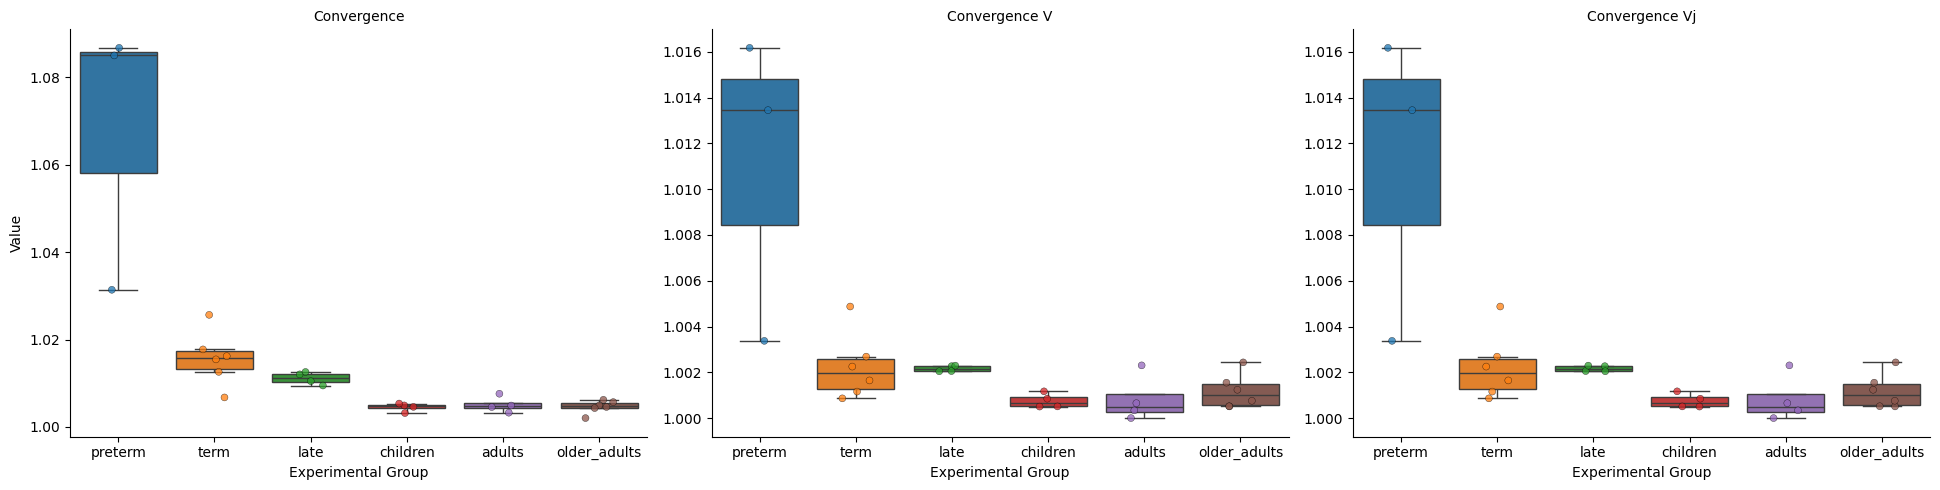

In [37]:
# Показываем конвергенцию и её варианты по экспериментальным группам.
rsplot.convergence(convergence,
                     metadata=metadata,
                     group="experimental_group",
                     height=5,
                     aspect=1.3
                  )

In [38]:
# Медианы convergence по группам.
convergence.merge(metadata, on="sample_id").groupby(
    "experimental_group", observed=True)[["convergence", "convergence_v", "convergence_vj"]].median().round(4)

,convergence,convergence_v,convergence_vj
experimental_group,,,
preterm,1.0850,1.0135,1.0135
term,1.0158,1.0019,1.0019
late,1.0113,1.0022,1.0022
children,1.0048,1.0007,1.0007
adults,1.0047,1.0005,1.0005
older_adults,1.0048,1.0010,1.0010


**Альфа-разнообразие — разнообразие *внутри* одного образца.** Несколько важных метрик:

- **`diversity`** — число обнаруженных клонотипов (богатство); чувствительно к глубине наблюдений.
- **`shannon_wiener`**: $H=-\sum_i p_i\ln p_i$; учитывает и богатство, и равномерность частот.
- **`norm_shannon_wiener`**: нормированная мера равномерности, обычно $H/\ln S$ (при $S>1$); ближе к 1, если частоты более равномерны.
- **`clonality`** — показатель противоположной направленности: больший вклад немногих клонов означает более выраженную клональность.
- Дополнительные метрики в таблице (`chao1`, `simpson`, `inverse_simpson`, `d50`, `gini_coefficient` и др.) по-разному чувствительны к редким и частым клонотипам.

`iterations=3` повторяет случайное субсэмплирование несколько раз; сравнивайте группы по распределению **образцов**, не воспринимая эти повторы как новые независимые биологические реплики. В данном примере настройка `seed` в самой функции и в фильтре могут различаться — ориентируйтесь на параметры расчёта в её логе.

## Diversity stats

In [39]:
# Считаем несколько индексов альфа-разнообразия на одинаковой глубине.
# # iterations=3 повторяет случайный выбор; это не три биологических образца.
diversity_stats = stats.calc_diversity_stats(clonosets_cd8,
                                             cl_filter=downsample_filter, seed=123, cpu=2,
                                             iterations=3,
                                             drop_small_samples=False, 
                                             verbose=True
                                            )
diversity_stats

CalcDiversityStats settings: seed=123, downsample=6300, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): c4_nCD8_TRB_1, UCB5_nCD8_TRB_1, a12_nCD8_TRB_1, o4_nCD8_TRB_1, UCB13_nCD8_TRB_1, a6_nCD8_TRB_1, UCB2_nCD8_TRB_1, o3_nCD8_TRB_1, UCB4_nCD8_TRB_1, c5_nCD8_TRB_1, o2_nCD8_TRB_1, UCB3_nCD8_TRB_1, UCB12_nCD8_TRB_1, c2_nCD8_TRB_1, o1_nCD8_TRB_1, a4_nCD8_TRB_1, UCB11_nCD8_TRB_1, c1_nCD8_TRB_1, UCB8_nCD8_TRB_1, o6_nCD8_TRB_1, UCB7_nCD8_TRB_1, a5_nCD8_TRB_1, UCB10_nCD8_TRB_1, UCB6_nCD8_TRB_1, UCB1_nCD8_TRB_2, o7_nCD8_TRB_1, UCB9_nCD8_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcDiversityStats |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,c4_nCD8_TRB_1,TRB,5956.0,0.997393,0.002607,8.669490,58749.033223,5956.0,63415.437261,0.105079,0.471122,0.000179,5599.604966,0.999821,0.001429,0.051900
1,UCB5_nCD8_TRB_1,TRB,5785.0,0.995864,0.004136,8.627189,42949.460938,5785.0,42928.050275,0.151905,0.455488,0.000191,5244.450317,0.999809,0.001746,0.076292
2,a12_nCD8_TRB_1,TRB,6176.0,0.999069,0.000931,8.720301,174605.082569,6176.0,175910.372281,0.038095,0.489961,0.000165,6044.776119,0.999835,0.000635,0.019335
3,o4_nCD8_TRB_1,TRB,3416.0,0.957828,0.042172,7.793108,6298.050136,3416.0,6504.411087,0.672540,0.237119,0.001476,677.511864,0.998524,0.031270,0.349477
4,UCB13_nCD8_TRB_1,TRB,6066.0,0.998310,0.001690,8.695734,88177.009615,6066.0,87677.466509,0.072222,0.480712,0.000171,5841.919341,0.999829,0.000476,0.035860
5,a6_nCD8_TRB_1,TRB,6136.0,0.998753,0.001247,8.711048,128705.541096,6136.0,134580.522483,0.050317,0.486636,0.000168,5959.459459,0.999832,0.000794,0.025425
6,UCB2_nCD8_TRB_1,TRB,6077.0,0.998409,0.001591,8.698404,90758.359606,6077.0,90448.303827,0.069206,0.481652,0.000170,5866.095182,0.999830,0.000476,0.034209
7,o3_nCD8_TRB_1,TRB,4205.0,0.970887,0.029113,8.101111,10098.310881,4205.0,10399.088735,0.521111,0.266825,0.000718,1393.218197,0.999282,0.014603,0.271769
8,UCB4_nCD8_TRB_1,TRB,5364.0,0.993518,0.006482,8.531804,19699.688889,5364.0,19844.560015,0.278730,0.412752,0.000213,4703.721261,0.999787,0.000794,0.128371
9,c5_nCD8_TRB_1,TRB,6069.0,0.998358,0.001642,8.696644,87095.672986,6069.0,86826.220717,0.071746,0.480969,0.000171,5852.255972,0.999829,0.000476,0.035387


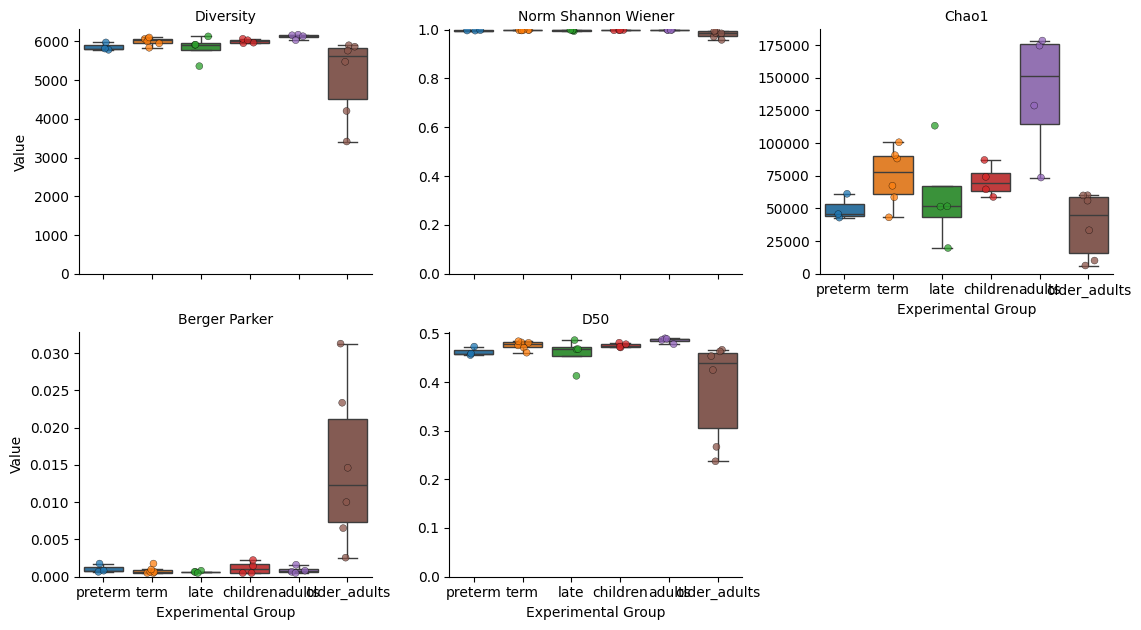

In [40]:
# Визуализируем богатство, равномерность, клональность и другие индексы.
rsplot.diversity_stats(diversity_stats,
                     metadata=metadata,
                     group="experimental_group"
                    )

In [41]:
# Медианы метрик разнообразия по группам (повторы субсэмплирования сначала усредняем внутри образца).
div_cols = ["diversity", "shannon_wiener", "norm_shannon_wiener", "clonality", "goods_coverage", "berger_parker"]
div_cols = [c for c in div_cols if c in diversity_stats.columns]
div_per_sample = diversity_stats.groupby("sample_id")[div_cols].mean().reset_index().merge(metadata, on="sample_id")
display(div_per_sample.groupby("experimental_group", observed=True)[div_cols].median().round(4))

# Образцы с самой высокой клональностью (berger_parker = доля крупнейшего клонотипа).
div_per_sample.sort_values("clonality", ascending=False)[["sample_id", "experimental_group"] + div_cols].head(6).round(4)

,diversity,shannon_wiener,norm_shannon_wiener,clonality,goods_coverage,berger_parker
experimental_group,,,,,,
preterm,5817.0,8.6356,0.9962,0.0038,0.1429,0.0008
term,6035.0,8.6888,0.9981,0.0019,0.0819,0.0006
late,5916.5,8.6619,0.9973,0.0027,0.1180,0.0006
children,6001.0,8.6791,0.9978,0.0022,0.0909,0.0010
adults,6148.5,8.7128,0.9987,0.0013,0.0455,0.0007
older_adults,5620.0,8.5107,0.9858,0.0142,0.1740,0.0123


,sample_id,experimental_group,diversity,shannon_wiener,norm_shannon_wiener,clonality,goods_coverage,berger_parker
24,o4_nCD8_TRB_1,older_adults,3416.0,7.7931,0.9578,0.0422,0.6725,0.0313
23,o3_nCD8_TRB_1,older_adults,4205.0,8.1011,0.9709,0.0291,0.5211,0.0146
26,o7_nCD8_TRB_1,older_adults,5764.0,8.5271,0.9847,0.0153,0.1333,0.0233
22,o2_nCD8_TRB_1,older_adults,5476.0,8.4944,0.9868,0.0132,0.2148,0.0100
7,UCB4_nCD8_TRB_1,late,5364.0,8.5318,0.9935,0.0065,0.2787,0.0008
25,o6_nCD8_TRB_1,older_adults,5866.0,8.6298,0.9946,0.0054,0.1225,0.0065


**Rarefaction (кривые разрежения).** Для каждого образца считаем, сколько различных клонотипов обнаружилось бы при разных глубинах выборки. По оси X — `rarefaction_depth` (число наблюдений), по оси Y — ожидаемое обнаруженное богатство `diversity`.

Если кривая выходит на плато, новые наблюдения добавляют мало новых клонотипов. Для TCR-репертуара всего организма плато часто недостижимо на небольшом образце крови. **Не путать** насыщение секвенирования конкретной библиотеки ридами с насыщением биологического репертуара организма. Два графика отличаются только логарифмической/линейной шкалой X.

## Rarefaction

In [42]:
# Для каждого образца вычисляем богатство при нескольких глубинах наблюдений.
rarefaction_points_ucb = stats.calc_rarefaction_curve(clonosets_cd8, cl_filter=clf.Filter(functionality="f", by_umi=True))
rarefaction_points_ucb

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcRarefactionPoints |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,rarefaction_depth,diversity
0,UCB10_nCD8_TRB_1,TRB,32,32.000000
1,UCB10_nCD8_TRB_1,TRB,100,100.000000
2,UCB10_nCD8_TRB_1,TRB,316,315.666667
3,UCB10_nCD8_TRB_1,TRB,1000,994.666667
4,UCB10_nCD8_TRB_1,TRB,3162,3107.333333
...,...,...,...,...
202,o7_nCD8_TRB_1,TRB,100,99.000000
203,o7_nCD8_TRB_1,TRB,316,304.333333
204,o7_nCD8_TRB_1,TRB,1000,962.000000
205,o7_nCD8_TRB_1,TRB,3162,2977.666667


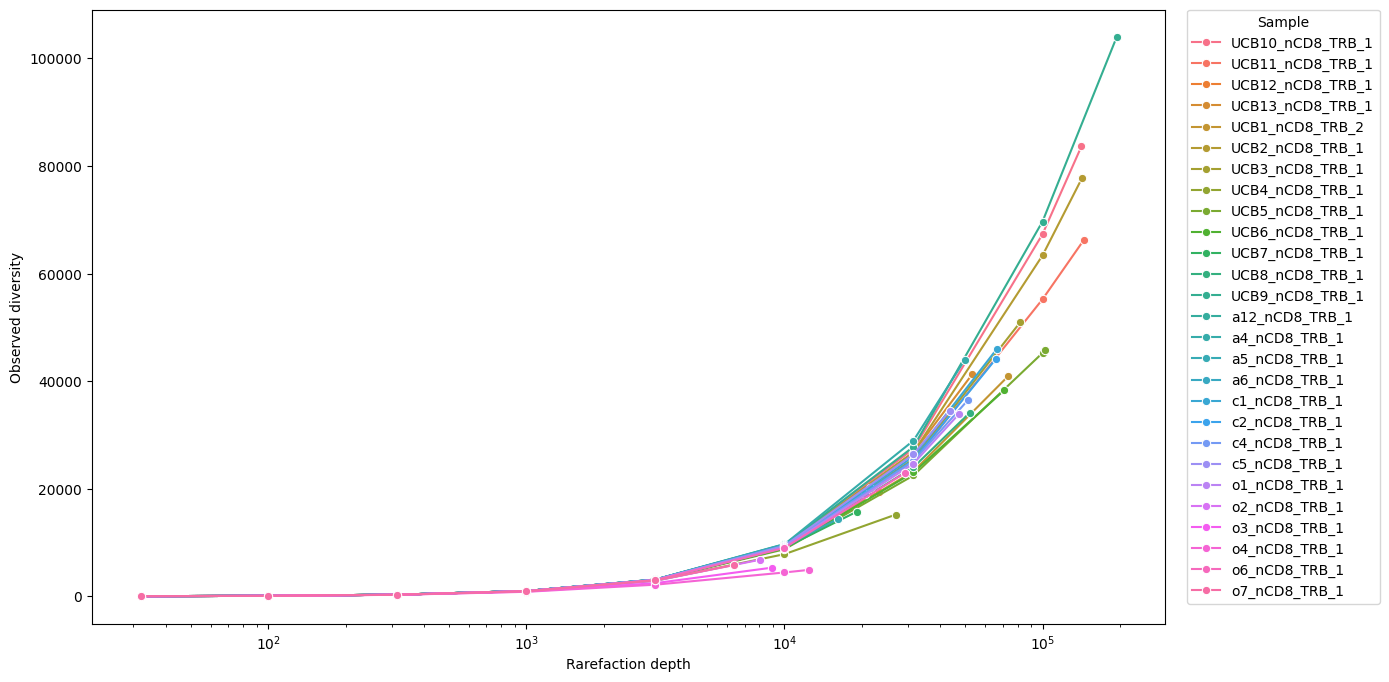

In [43]:
# Строим rarefaction с логарифмической шкалой глубины для обзора широкого диапазона.
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=True, aspect=2, height=7)

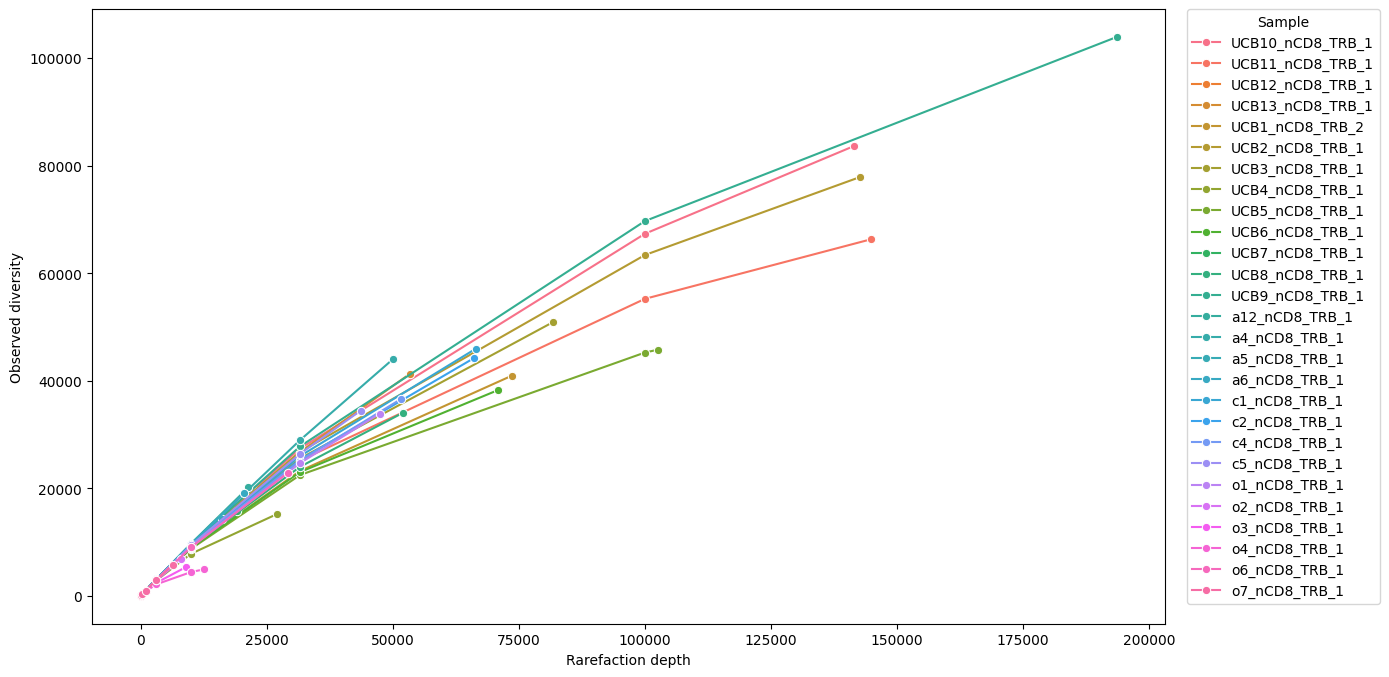

In [44]:
# Строим ту же кривую с обычной шкалой глубины для оценки формы роста.
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=False, aspect=2, height=7)

**Бета-разнообразие — сходство *между* образцами.** Мы сравниваем не просто численность клонов, а пересечение определённых последовательностей. В этом ноутбуке совпадение задаётся `overlap_type='aaV'`: **одинаковая аминокислотная CDR3 и один V-ген**. Совпадение только CDR3aa без учёта V — менее строгое правило.

Для двух репертуаров $A$ и $B$ метрика **F2** выражается как $F_2(A,B)=\sum_{i\in A\cap B}\sqrt{p_iq_i}$, где $p_i$, $q_i$ — частоты совпавшего клонотипа в каждом образце. Чем больше F2, тем выше сходство по совпадающим последовательностям с учётом их частот. Диагональ матрицы при одинаковых правилах определения клонотипа равна 1; почти нулевые значения между людьми ожидаемы из-за индивидуального разнообразия TCR.

Это **описательная мера сходства**, а не p-value и не результат теста на различия между экспериментальными группами.

## Beta-diversity

### Main function for beta-diversity 

**`beta.metrics`** function calculates a diverse set of Beta-diversity metrics which include (for more detailed explanation refer to **THIS LINK**):

- Number of intersecting clonotypes ('number_of_intersecting_clonotypes')
- Relative diversity ('relative_diversity')
- Pearson correlation ('pearson')
- F1 ('f1') metric - geometric mean of total frequencies of intersecting clonotypes in both samples
- F2 ('f2') metric - sum of geometric means of frequencies of each clonotype in the samples
- ', 'f1', 'f2', 'jaccard', 'jaccard_distance', 'dice', 'dice_distance', 'szymkiewicz_simpson', 'bray_curtis', 'l1', 'total_variation', 'l2', 'morisita_horn', 'jensen_shannon', 'kl_divergence', 'hellinger', 'full_table'

Required input is only the sample_df - DataFrame with the set of repertoires

By default it outputs a dictionary, containing metrics as keys and DataFrames with each metric (or mainly matrices) as values.

In [45]:
# Считаем попарное сходство клоносетов и таблицы пересечений.
# # aaV означает совпадение CDR3aa И V-гена; значение F2 — сходство, не расстояние.
beta_diversity = beta.metrics(clonosets_cd8,                     # <- clonosets_df - DataFrame with clonosets - sample_id, filename
                              cl_filter=downsample_filter,        # <- you can use a filter to preprocess all the clonosets before intersecting
                              overlap_type="aaV",                     # <- overlap type - is a defenition of similar clonotypes. aaV = similar clonotypes have same CDR3 amino acid sequence and same V gene, and we are not concidering V gene
                              clonosets_df2=None,                     # <- you can pass a second set of clonosets for intersection, otherwise it will intersect all possible pairs with each other
                              cl_filter2=None,                        # <- you can pass a different filter for second set of clonosets, otherwise it will be preprocessed with cl_filter
                              metrics=None,                           # <- you can limit the metrics to a list or a single metric for simplicity of the output
                              cpu=None                                # <- cpus for parallel calculation (=None means - take all avaiable)
                              )

Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV
Reading clonosets |##################################################| 27/27 sample(s) processed
Using all available worker processes by default. Set cpu=1 or another integer to change this.
Intersecting clonosets |##################################################| 351/351 pairs processed


In [46]:
# Смотрим, какие метрики и таблицы вернула функция beta.metrics.
beta_diversity.keys()

dict_keys(['number_of_intersecting_clonotypes', 'relative_diversity', 'pearson', 'f1', 'f2', 'jaccard', 'jaccard_distance', 'dice', 'dice_distance', 'szymkiewicz_simpson', 'bray_curtis', 'l1', 'total_variation', 'l2', 'morisita_horn', 'jensen_shannon', 'kl_divergence', 'hellinger', 'full_table'])

In [47]:
# Отдельно открываем квадратную матрицу попарного сходства F2.
beta_diversity["f2"]

sample2,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB12_nCD8_TRB_1,UCB13_nCD8_TRB_1,UCB1_nCD8_TRB_2,UCB2_nCD8_TRB_1,UCB3_nCD8_TRB_1,UCB4_nCD8_TRB_1,UCB5_nCD8_TRB_1,UCB6_nCD8_TRB_1,...,c1_nCD8_TRB_1,c2_nCD8_TRB_1,c4_nCD8_TRB_1,c5_nCD8_TRB_1,o1_nCD8_TRB_1,o2_nCD8_TRB_1,o3_nCD8_TRB_1,o4_nCD8_TRB_1,o6_nCD8_TRB_1,o7_nCD8_TRB_1
sample1,,,,,,,,,,,,,,,,,,,,,
UCB10_nCD8_TRB_1,1.000000,0.009535,0.004413,0.005791,0.014239,0.004193,0.005249,0.004464,0.017403,0.004073,...,0.002222,0.002961,0.000952,0.002288,0.003727,0.001971,0.001336,0.000910,0.001928,0.002419
UCB11_nCD8_TRB_1,0.009535,1.000000,0.007044,0.009278,0.027862,0.008130,0.012237,0.006979,0.025906,0.005682,...,0.002694,0.003279,0.002694,0.003213,0.002896,0.004270,0.001928,0.002218,0.001849,0.003651
UCB12_nCD8_TRB_1,0.004413,0.007044,1.000000,0.006128,0.014541,0.005091,0.005943,0.004487,0.015323,0.002671,...,0.001587,0.001994,0.001177,0.002737,0.002362,0.002578,0.001243,0.001041,0.001018,0.002036
UCB13_nCD8_TRB_1,0.005791,0.009278,0.006128,1.000000,0.015951,0.005930,0.008661,0.005535,0.015816,0.003082,...,0.002737,0.003244,0.002470,0.002392,0.001336,0.004454,0.000476,0.000542,0.000859,0.002880
UCB1_nCD8_TRB_2,0.014239,0.027862,0.014541,0.015951,1.000000,0.016324,0.027977,0.013722,0.059184,0.010630,...,0.003213,0.005698,0.003128,0.007878,0.003811,0.006807,0.001785,0.004097,0.002377,0.003793
UCB2_nCD8_TRB_1,0.004193,0.008130,0.005091,0.005930,0.016324,1.000000,0.008045,0.005273,0.017698,0.003980,...,0.001746,0.002745,0.002288,0.001719,0.001878,0.002743,0.000817,0.001049,0.001227,0.003503
UCB3_nCD8_TRB_1,0.005249,0.012237,0.005943,0.008661,0.027977,0.008045,1.000000,0.007030,0.024041,0.004138,...,0.002452,0.002419,0.002222,0.003395,0.002195,0.003587,0.001344,0.001813,0.001560,0.003422
UCB4_nCD8_TRB_1,0.004464,0.006979,0.004487,0.005535,0.013722,0.005273,0.007030,1.000000,0.015067,0.004254,...,0.002536,0.002269,0.002036,0.002868,0.001785,0.001692,0.000976,0.001308,0.001185,0.002419
UCB5_nCD8_TRB_1,0.017403,0.025906,0.015323,0.015816,0.059184,0.017698,0.024041,0.015067,1.000000,0.009636,...,0.005029,0.004955,0.002087,0.006775,0.003223,0.005656,0.001018,0.002732,0.002919,0.004545


In [48]:
# Средний F2 внутри групп и между группами (диагональ исключаем).
import numpy as np
f2 = beta_diversity["f2"]
f2_pairs = f2.where(~np.eye(len(f2), dtype=bool)).stack().rename("f2").reset_index()
f2_pairs.columns = ["sample_id_1", "sample_id_2", "f2"]
group_of = metadata.set_index("sample_id")["experimental_group"]
f2_pairs["group_1"] = f2_pairs["sample_id_1"].map(group_of)
f2_pairs["group_2"] = f2_pairs["sample_id_2"].map(group_of)
print("Медиана F2 по всем парам:", round(f2_pairs["f2"].median(), 5))
f2_pairs.groupby(["group_1", "group_2"], observed=True)["f2"].mean().unstack().round(4)

Медиана F2 по всем парам: 0.00206


group_2,preterm,term,late,children,adults,older_adults
group_1,,,,,,
preterm,0.0377,0.0140,0.0102,0.0042,0.0039,0.0033
term,0.0140,0.0052,0.0045,0.0022,0.0021,0.0019
late,0.0102,0.0045,0.0037,0.0021,0.0017,0.0016
children,0.0042,0.0022,0.0021,0.0011,0.0010,0.0010
adults,0.0039,0.0021,0.0017,0.0010,0.0011,0.0011
older_adults,0.0033,0.0019,0.0016,0.0010,0.0011,0.0007


In [49]:
# Самые похожие пары образцов (каждая пара один раз).
f2_unique = f2_pairs[f2_pairs["sample_id_1"] < f2_pairs["sample_id_2"]]
f2_unique.sort_values("f2", ascending=False).head(8).round(4)

,sample_id_1,sample_id_2,f2,group_1,group_2
111,UCB1_nCD8_TRB_2,UCB5_nCD8_TRB_1,0.0592,preterm,preterm
109,UCB1_nCD8_TRB_2,UCB3_nCD8_TRB_1,0.0280,preterm,term
29,UCB11_nCD8_TRB_1,UCB1_nCD8_TRB_2,0.0279,preterm,preterm
33,UCB11_nCD8_TRB_1,UCB5_nCD8_TRB_1,0.0259,preterm,preterm
163,UCB3_nCD8_TRB_1,UCB5_nCD8_TRB_1,0.0240,term,preterm
137,UCB2_nCD8_TRB_1,UCB5_nCD8_TRB_1,0.0177,term,preterm
7,UCB10_nCD8_TRB_1,UCB5_nCD8_TRB_1,0.0174,term,preterm
108,UCB1_nCD8_TRB_2,UCB2_nCD8_TRB_1,0.0163,preterm,term


In [50]:
# Проверка родства: не из одной ли семьи самые похожие образцы.
metadata_raw.query("subset == 'nCD8'")[["sample_id", "experimental_group", "family", "sex", "gestational_age"]].sort_values("family")

,sample_id,experimental_group,family,sex,gestational_age
15,c2_nCD8_TRB_1,children,c2_c3_siblings,F,NaN
13,o4_nCD8_TRB_1,older_adults,o4_o5_siblings,M,NaN
1,o1_nCD8_TRB_1,older_adults,NaN,M,NaN
4,o3_nCD8_TRB_1,older_adults,NaN,M,NaN
9,o6_nCD8_TRB_1,older_adults,NaN,M,NaN
11,o2_nCD8_TRB_1,older_adults,NaN,M,NaN
12,o7_nCD8_TRB_1,older_adults,NaN,M,NaN
18,c1_nCD8_TRB_1,children,NaN,F,NaN
22,c4_nCD8_TRB_1,children,NaN,M,NaN
24,c5_nCD8_TRB_1,children,NaN,M,NaN


In [51]:
# Разбираем пересечение самой похожей по F2 пары образцов на уровне клонотипов.
import numpy as np
f2 = beta_diversity["f2"]
s1, s2 = f2.where(~np.eye(len(f2), dtype=bool)).stack().idxmax()
print("Самая похожая пара:", s1, s2, "F2 =", round(f2.loc[s1, s2], 4))
full_table = beta_diversity["full_table"]
full_table[full_table["pair"].str.contains(s1) & full_table["pair"].str.contains(s2)]

Самая похожая пара: UCB1_nCD8_TRB_2 UCB5_nCD8_TRB_1 F2 = 0.0592


,cdr3aa,v,sample1_count,sample2_count,sample1_freq,sample2_freq,sample1,sample2,pair
1169489,CASSSGGGYTF,TRBV27,0,1,0.000000,0.000159,UCB1_nCD8_TRB_2,UCB5_nCD8_TRB_1,UCB1_nCD8_TRB_2_vs_UCB5_nCD8_TRB_1
1169490,CASSLASSYNEQFF,TRBV7-6,0,1,0.000000,0.000159,UCB1_nCD8_TRB_2,UCB5_nCD8_TRB_1,UCB1_nCD8_TRB_2_vs_UCB5_nCD8_TRB_1
1169491,CASSQVQGSTTGELFF,TRBV3-1,1,0,0.000159,0.000000,UCB1_nCD8_TRB_2,UCB5_nCD8_TRB_1,UCB1_nCD8_TRB_2_vs_UCB5_nCD8_TRB_1
1169492,CASSQDRGYGYTF,TRBV3-1,1,0,0.000159,0.000000,UCB1_nCD8_TRB_2,UCB5_nCD8_TRB_1,UCB1_nCD8_TRB_2_vs_UCB5_nCD8_TRB_1
1169493,CASSFVGAWETQYF,TRBV7-9,1,0,0.000159,0.000000,UCB1_nCD8_TRB_2,UCB5_nCD8_TRB_1,UCB1_nCD8_TRB_2_vs_UCB5_nCD8_TRB_1
...,...,...,...,...,...,...,...,...,...
1180548,CASSSPGLAGQETQYF,TRBV12-3,0,1,0.000000,0.000159,UCB1_nCD8_TRB_2,UCB5_nCD8_TRB_1,UCB1_nCD8_TRB_2_vs_UCB5_nCD8_TRB_1
1180549,CASRQYQETQYF,TRBV12-3,0,1,0.000000,0.000159,UCB1_nCD8_TRB_2,UCB5_nCD8_TRB_1,UCB1_nCD8_TRB_2_vs_UCB5_nCD8_TRB_1
1180550,CASSYRSSYNSPLHF,TRBV27,0,1,0.000000,0.000159,UCB1_nCD8_TRB_2,UCB5_nCD8_TRB_1,UCB1_nCD8_TRB_2_vs_UCB5_nCD8_TRB_1
1180551,CASSRQNTEAFF,TRBV4-2,0,1,0.000000,0.000159,UCB1_nCD8_TRB_2,UCB5_nCD8_TRB_1,UCB1_nCD8_TRB_2_vs_UCB5_nCD8_TRB_1


**Как читать тепловую карту F2.** Каждая ячейка — результат сравнения **пары образцов**, а не отдельного клонотипа. `ignore_diagonal=True` убирает тривиальные сравнения образца с самим собой; `hclust=True` упорядочивает образцы иерархической кластеризацией. На карте можно искать группы похожих образцов, но визуальный кластер сам по себе не гарантирует статистическую значимость.

### Single metric heatmap plot

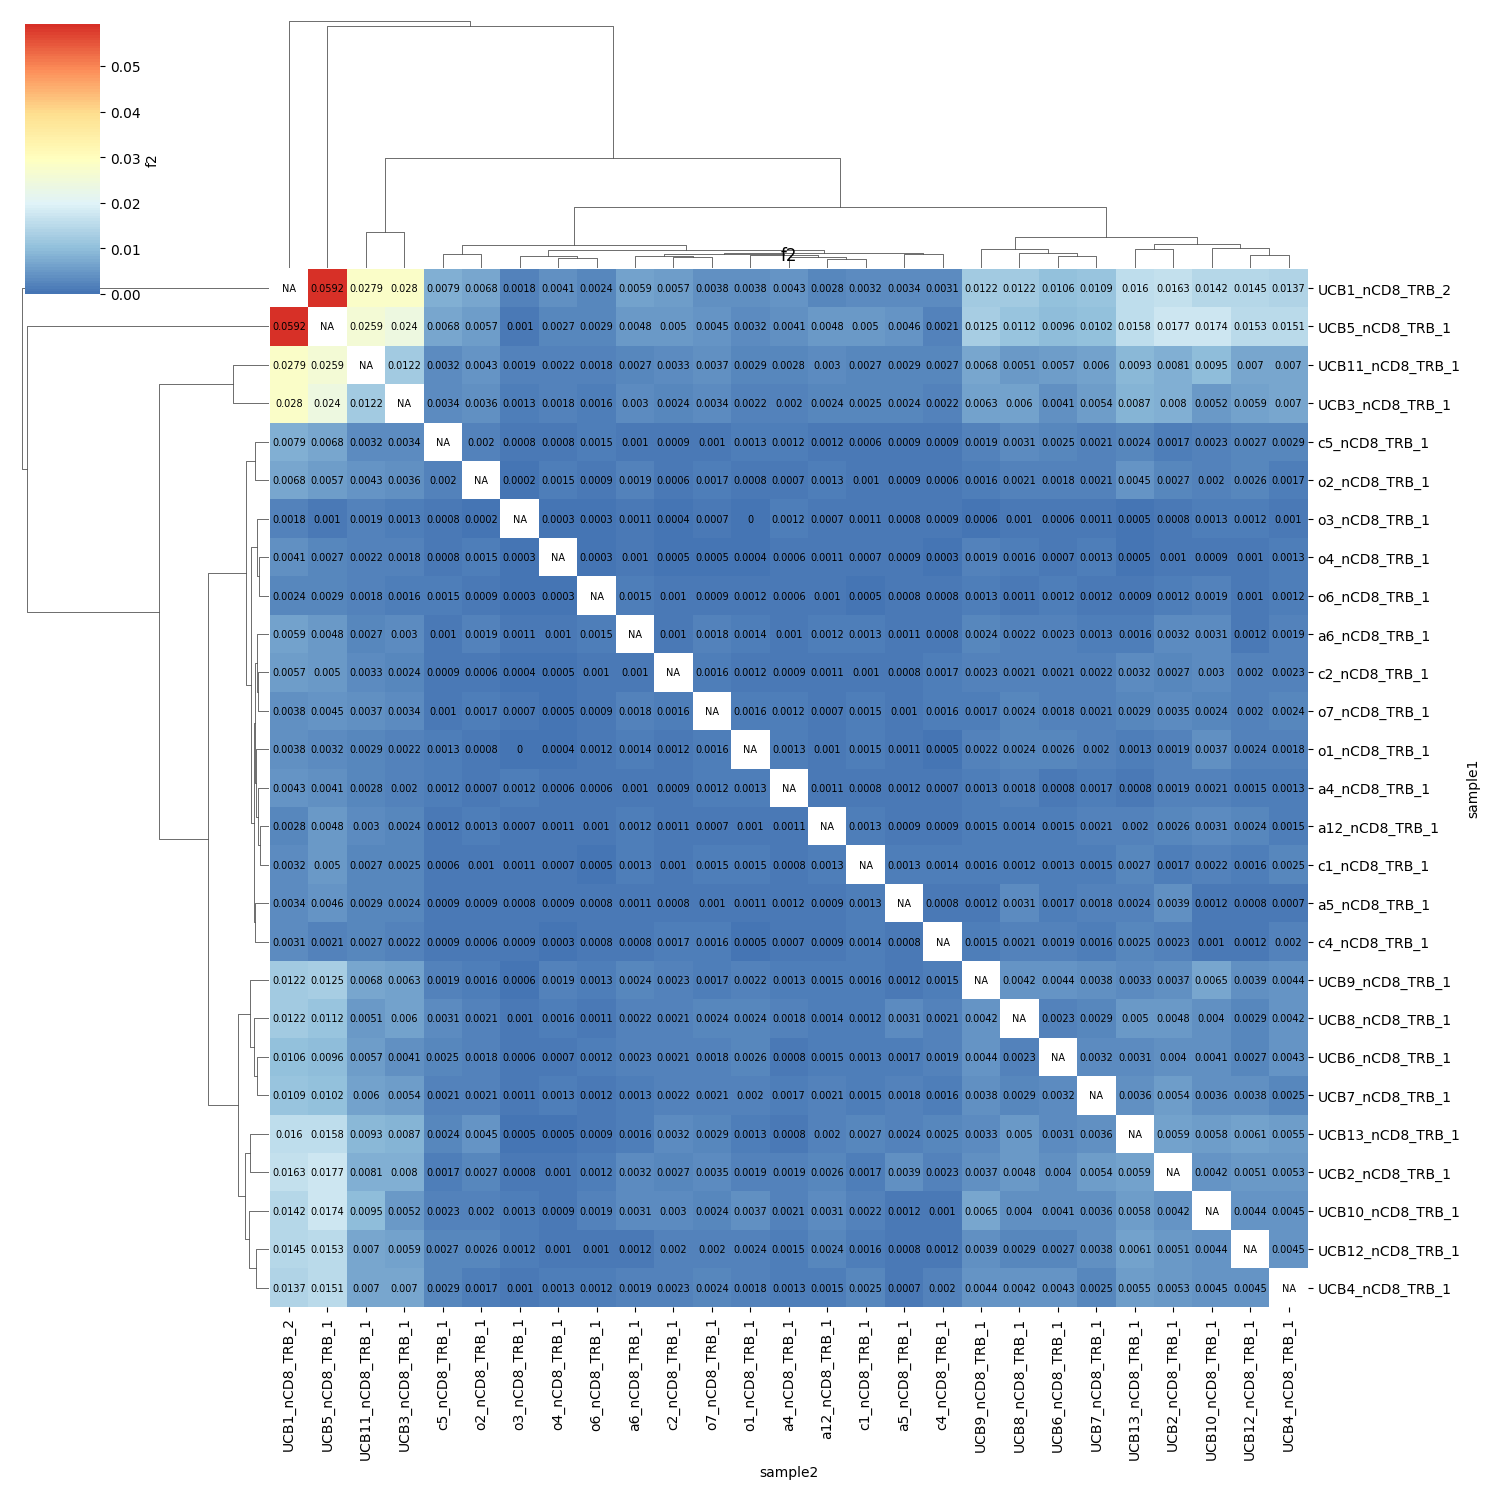

In [52]:
# Показываем тепловую карту F2, скрываем диагональ, кластеризуем образцы по сходству.
rsplot.beta_metric(beta_diversity,
                   metric="f2",
                   ignore_diagonal=True,
                   hclust=True,
                   log_values=False,
                   height = 15
                  )

**MDS (multidimensional scaling).** Это способ разместить образцы в двумерном пространстве так, чтобы **более близким** в смысле исходной матрицы расстояний объектам соответствовали более близкие точки. Мера F2 — *сходство*, поэтому для методов расстояний её преобразуют (например, в материалах семинара обсуждается $d_{ij}=-\log_{10}(F2_{ij}+\varepsilon)$ с малым $\varepsilon$). Конкретные внутренние вычисления определяет реализация `beta.mds`.

`MDS1` и `MDS2` — **условные координаты**, а не биологические параметры. `centroids=True` показывает центры групп, `dispersion=True` — разброс. Оцениваем, насколько образцы одной группы сближаются; не делаем вывод о значимости без отдельного статистического анализа.

### MDS for metric

In [53]:
# Преобразуем информацию о попарных отношениях между образцами в координаты MDS.
ucb_cd8_mds = beta.mds(beta_diversity)
ucb_cd8_mds

,sample_id,MDS1,MDS2
0,UCB10_nCD8_TRB_1,-0.119702,0.109313
1,UCB11_nCD8_TRB_1,0.072539,-0.064408
2,UCB12_nCD8_TRB_1,-0.037975,-0.027307
3,UCB13_nCD8_TRB_1,-0.216485,0.456566
4,UCB1_nCD8_TRB_2,-0.057867,-0.200320
5,UCB2_nCD8_TRB_1,-0.040462,0.129743
6,UCB3_nCD8_TRB_1,0.029476,-0.098022
7,UCB4_nCD8_TRB_1,-0.012638,0.224210
8,UCB5_nCD8_TRB_1,-0.180211,-0.152787
9,UCB6_nCD8_TRB_1,-0.264748,0.383771


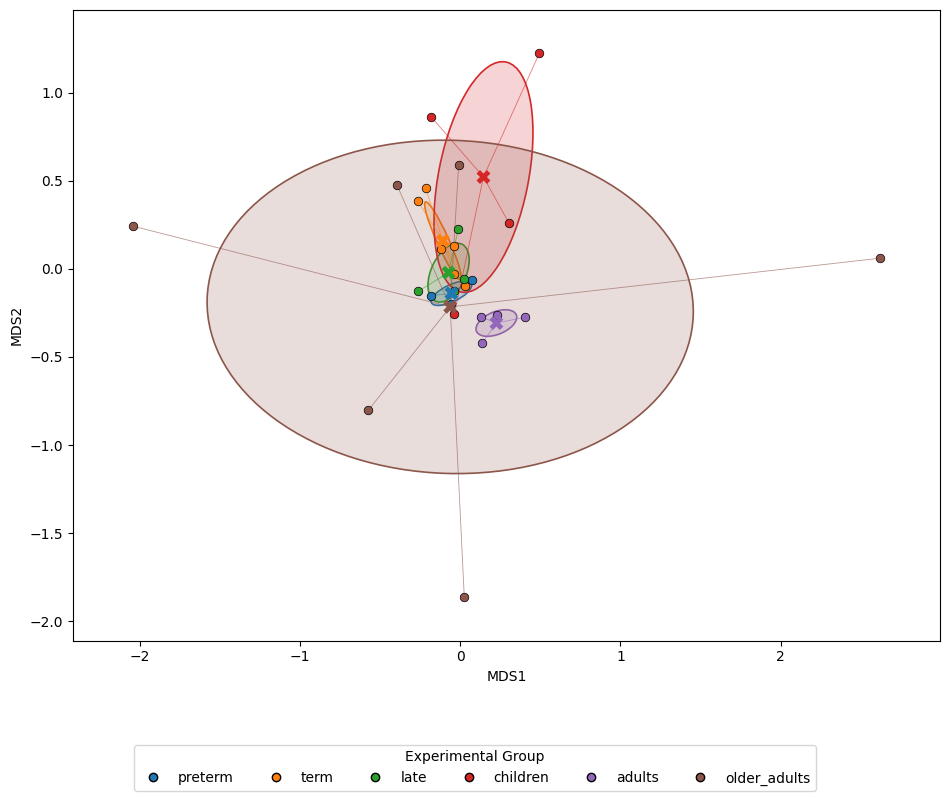

In [54]:
# Рисуем две координаты MDS с цветом групп, центрами и разбросом.
rsplot.beta_mds(ucb_cd8_mds, metadata=metadata, group="experimental_group", centroids=True, dispersion=True, height=8)

**Кластеризация похожих CDR3.** Здесь **объекты — последовательности клонотипов**, а не образцы. Если две последовательности удовлетворяют правилу сходства, между ними можно провести ребро графа. `overlap_type='aaV'` использует аминокислотные CDR3 и V-ген, `mismatches=1` допускает одно несовпадение между сравниваемыми последовательностями.

Важная деталь: в связанном кластере две далёкие вершины могут отличаться **более чем на один символ**, поскольку соединяются цепочкой промежуточных вариантов. Такие кластеры — кандидаты для последующего поиска общей специфичности, но не прямое доказательство распознавания одного антигена. Расчёт и отрисовка могут быть тяжёлыми на больших данных.

## Clustering

### Create clusters

In [55]:
# Создаём пустой объект, в котором будут храниться клонотипы и связи между ними.
clusters = clustering.Clusters()
clusters

Clusters state:
  State: empty
Clonotypes: not read
Clusters: not created
Metadata: not added
Node Pgen: not calculated
ALICE: not calculated

In [56]:
# Загружаем отфильтрованные клонотипы всех выбранных образцов в объект кластеризации.
clusters.read_from_clonosets_df(clonosets_cd8, cl_filter=downsample_filter)

Pooled 156113 clonotypes from 27 samples


In [57]:
# Соединяем близкие по CDR3aa клонотипы с одинаковым V-геном, допуская один mismatch.
clusters.create_clusters(overlap_type='aaV', mismatches=1)

Nodes list created: 156113 nodes
Using all available worker processes by default. Set cpu=1 or another integer to change this.
Find neighbour clonotypes |##################################################| 737/737 tasks processed
found 96348 edges
-----------------------------
NexworkX graph created
Found 8264 clusters (2 or more nodes) and 112437 single nodes. Total: 120701


In [58]:
# Добавляем к вершинам/последовательностям метаданные экспериментальных групп.
clusters.add_metadata(metadata)

In [59]:
# Преобразуем граф кластеризации в обычную таблицу для просмотра и фильтрации.
clusters_df = clusters.as_dataframe()
clusters_df

,cluster_no,node_id,cdr3aa,v,j,cdr3nt,sample_id,freq,count,isotype,n_neighbours,experimental_group,donor_id,subset,source
0,0,131706,CASSLGATEAFF,TRBV12-3,TRBJ1-1,TGTGCCAGCAGTTTAGGGGCCACTGAAGCTTTCTTT,o1_nCD8_TRB_1,0.000159,1,None,35,older_adults,o1,nCD8,PB
1,0,146191,CASSPNSYEQYF,TRBV12-3,TRBJ2-7,TGTGCCAGCAGCCCTAACAGCTACGAGCAGTACTTC,UCB4_nCD8_TRB_1,0.000159,1,None,5,late,UCB4,nCD8,UCB
2,0,21559,CASNLGGDTQYF,TRBV12-3,TRBJ2-3,TGTGCCAGCAACCTAGGGGGAGATACGCAGTATTTT,UCB8_nCD8_TRB_1,0.000159,1,None,5,late,UCB8,nCD8,UCB
3,0,48989,CASSLGYNEQFF,TRBV12-3,TRBJ2-1,TGTGCCAGCAGTTTAGGGTACAATGAGCAGTTCTTC,UCB1_nCD8_TRB_2,0.000159,1,None,29,preterm,UCB1,nCD8,UCB
4,0,26634,CASSSASYEQYF,TRBV12-3,TRBJ2-7,TGTGCCAGCAGTTCTGCTAGCTACGAGCAGTACTTC,a4_nCD8_TRB_1,0.000159,1,None,5,adults,a4,nCD8,PB
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
156108,120696,47832,WPEKAGVISTEAFF,TRBV7-8,TRBJ1-1,TGGCCGGAAAAGGCTGGGGTTATTTCCACTGAAGCTTTCTTT,o7_nCD8_TRB_1,0.000159,1,None,0,older_adults,o7,nCD8,PB
156109,120697,46819,WREDTQYF,TRBV19,TRBJ2-3,TGGCGGGAAGATACGCAGTATTTT,o7_nCD8_TRB_1,0.000159,1,None,0,older_adults,o7,nCD8,PB
156110,120698,31568,WRRRNEKLFF,TRBV27,TRBJ1-4,TGGCGGCGGAGAAATGAAAAACTGTTTTTT,o1_nCD8_TRB_1,0.000159,1,None,0,older_adults,o1,nCD8,PB
156111,120699,45648,YASSLGLAGETQYF,TRBV5-1,TRBJ2-5,TACGCCAGCAGCTTGGGACTAGCGGGGGAGACCCAGTACTTC,UCB1_nCD8_TRB_2,0.000159,1,None,0,preterm,UCB1,nCD8,UCB


In [60]:
# Считаем характеристики кластеров: число вершин, рёбер, размер и консенсус.
cluster_properties = clusters.properties()
cluster_properties

Using all available worker processes by default. Set cpu=1 or another integer to change this.
Calculating cluster properties |###################-------------------------------| 47677/120701 clusters processed

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



Calculating cluster properties |#####################################-------------| 90619/120701 clusters processed

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



Calculating cluster properties |##################################################| 120701/120701 clusters processed


,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
0,0,cluster_0,824,5449,921,16,0.016070,12.091019,CASSLGGYEQYF,TGTGCCAGCAGTTTAGGGGGCGATGAGCAGTACTTC,TRBV12-3,TRBJ2-7
1,1,cluster_1,763,3433,815,20,0.011809,14.533421,CASSLGGGYEQYF,TGTGCCAGCAGTTTAGGGGGCGCCTACGAGCAGTACTTC,TRBV27,TRBJ2-7
2,2,cluster_2,572,2229,622,25,0.013649,19.440559,CASSLGGSYEQFF,TGTGCCAGCAGTTTAGGGGGGGACAATGAGCAGTTCTTC,TRBV12-3,TRBJ2-7
3,3,cluster_3,565,3017,620,16,0.018936,11.800000,CASSLGGYEQYF,TGTGCCAGCAGCTTAGGCGCCGACGAGCAGTACTTC,TRBV7-9,TRBJ2-7
4,4,cluster_4,514,2942,578,20,0.022315,14.607004,CASSLGGYEQFF,TGCGCCAGCAGCTTGGGCGGCAATGAGCAGTTCTTC,TRBV5-1,TRBJ2-7
...,...,...,...,...,...,...,...,...,...,...,...,...
120696,120696,cluster_120696,1,0,1,0,0.000000,0.000000,WPEKAGVISTEAFF,TGGCCGGAAAAGGCTGGGGTTATTTCCACTGAAGCTTTCTTT,TRBV7-8,TRBJ1-1
120697,120697,cluster_120697,1,0,1,0,0.000000,0.000000,WREDTQYF,TGGCGGGAAGATACGCAGTATTTT,TRBV19,TRBJ2-3
120698,120698,cluster_120698,1,0,1,0,0.000000,0.000000,WRRRNEKLFF,TGGCGGCGGAGAAATGAAAAACTGTTTTTT,TRBV27,TRBJ1-4
120699,120699,cluster_120699,1,0,1,0,0.000000,0.000000,YASSLGLAGETQYF,TACGCCAGCAGCTTGGGACTAGCGGGGGAGACCCAGTACTTC,TRBV5-1,TRBJ2-5


In [61]:
# Отбираем кластеры, исключая указанные V- и J-сегменты из демонстрации.
# # Поля concensus_v/concensus_j названы так в выводе библиотеки.
cluster_properties.query("concensus_v != 'TRBV5-1' and concensus_j not in ['TRBJ2-7', 'TRBJ2-3', 'TRBJ1-2']")

,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
14,14,cluster_14,242,953,259,15,0.032681,11.619835,CASSQDGNEQYF,TGCGCCAGCAGCCAAGACGGCGATGAGCAGTACTTC,TRBV4-1,TRBJ2-1
20,20,cluster_20,185,1181,202,9,0.069389,6.535135,CASSLGGNTEAFF,TGTGCCAGCAGTTTAGGGGGGAACACTGAAGCTTTCTTT,TRBV27,TRBJ1-1
23,23,cluster_23,160,1407,176,11,0.110613,7.687500,CASSLGGTEAFF,TGTGCCAGCAGCTTAGGGGACACTGAAGCTTTCTTT,TRBV7-9,TRBJ1-1
25,25,cluster_25,145,474,160,14,0.045402,10.813793,CASSLGGNTEAFF,TGTGCCAGCAGCTTAGGGGGGAACACTGAAGCTTTCTTT,TRBV7-9,TRBJ1-1
26,26,cluster_26,140,934,158,9,0.095992,6.921429,CASSLGGNQPQHF,TGTGCCAGCAGTTTAGGGGGCAATCAGCCCCAGCATTTT,TRBV27,TRBJ1-5
...,...,...,...,...,...,...,...,...,...,...,...,...
120691,120691,cluster_120691,1,0,2,0,0.000000,0.000000,WDNTGELFF,TGGGACAACACCGGGGAGCTGTTTTTT,TRBV9,TRBJ2-2
120693,120693,cluster_120693,1,0,1,0,0.000000,0.000000,WGTESYNSPLHF,TGGGGAACTGAGTCCTATAATTCACCCCTCCACTTT,TRBV7-3,TRBJ1-6
120696,120696,cluster_120696,1,0,1,0,0.000000,0.000000,WPEKAGVISTEAFF,TGGCCGGAAAAGGCTGGGGTTATTTCCACTGAAGCTTTCTTT,TRBV7-8,TRBJ1-1
120698,120698,cluster_120698,1,0,1,0,0.000000,0.000000,WRRRNEKLFF,TGGCGGCGGAGAAATGAAAAACTGTTTTTT,TRBV27,TRBJ1-4


In [62]:
# Смотрим сводное представление объекта кластеров.
clusters

Clusters state:
  Completed: clonotypes read, clusters created, metadata added
Clonotypes:
    source: clonosets_df
    clonotypes: 156113
    samples: 27
    input_samples: 27
    filter:
      name: default_filter
      functionality: f
      downsample_size: 6300
      top: None
      by_umi: True
      mix_tails: False
      seed: 100
      count_threshold: None
      unweight: False
      recount_fractions: True
      white_list: []
      black_list: []
      pool_by: 
      convert: True
      ignore_small_clonosets: False
      retain_alleles: False
Graph: 156113 nodes and 96348 edges
Clusters: 8264 clusters (2 or more nodes) and 112437 single nodes. Total: 120701
Clustering parameters:
    method: mismatches
    overlap_type: aaV
    mismatches: 1
Metadata columns: experimental_group, donor_id, subset, source
Node Pgen: not calculated
ALICE: not calculated

**Визуализация графа.** Вершины представляют последовательности/клонотипы, ребра — заданное выше сходство. Цвет показывает экспериментальную группу; подписи и размеры связаны с числом наблюдений. Здесь выводятся кластеры с номерами от 20 до 29; сами номера — **идентификаторы по результату текущего расчёта**, а не универсальные биологические метки. При другом входном наборе или параметрах их состав может измениться.

### Plot clusters

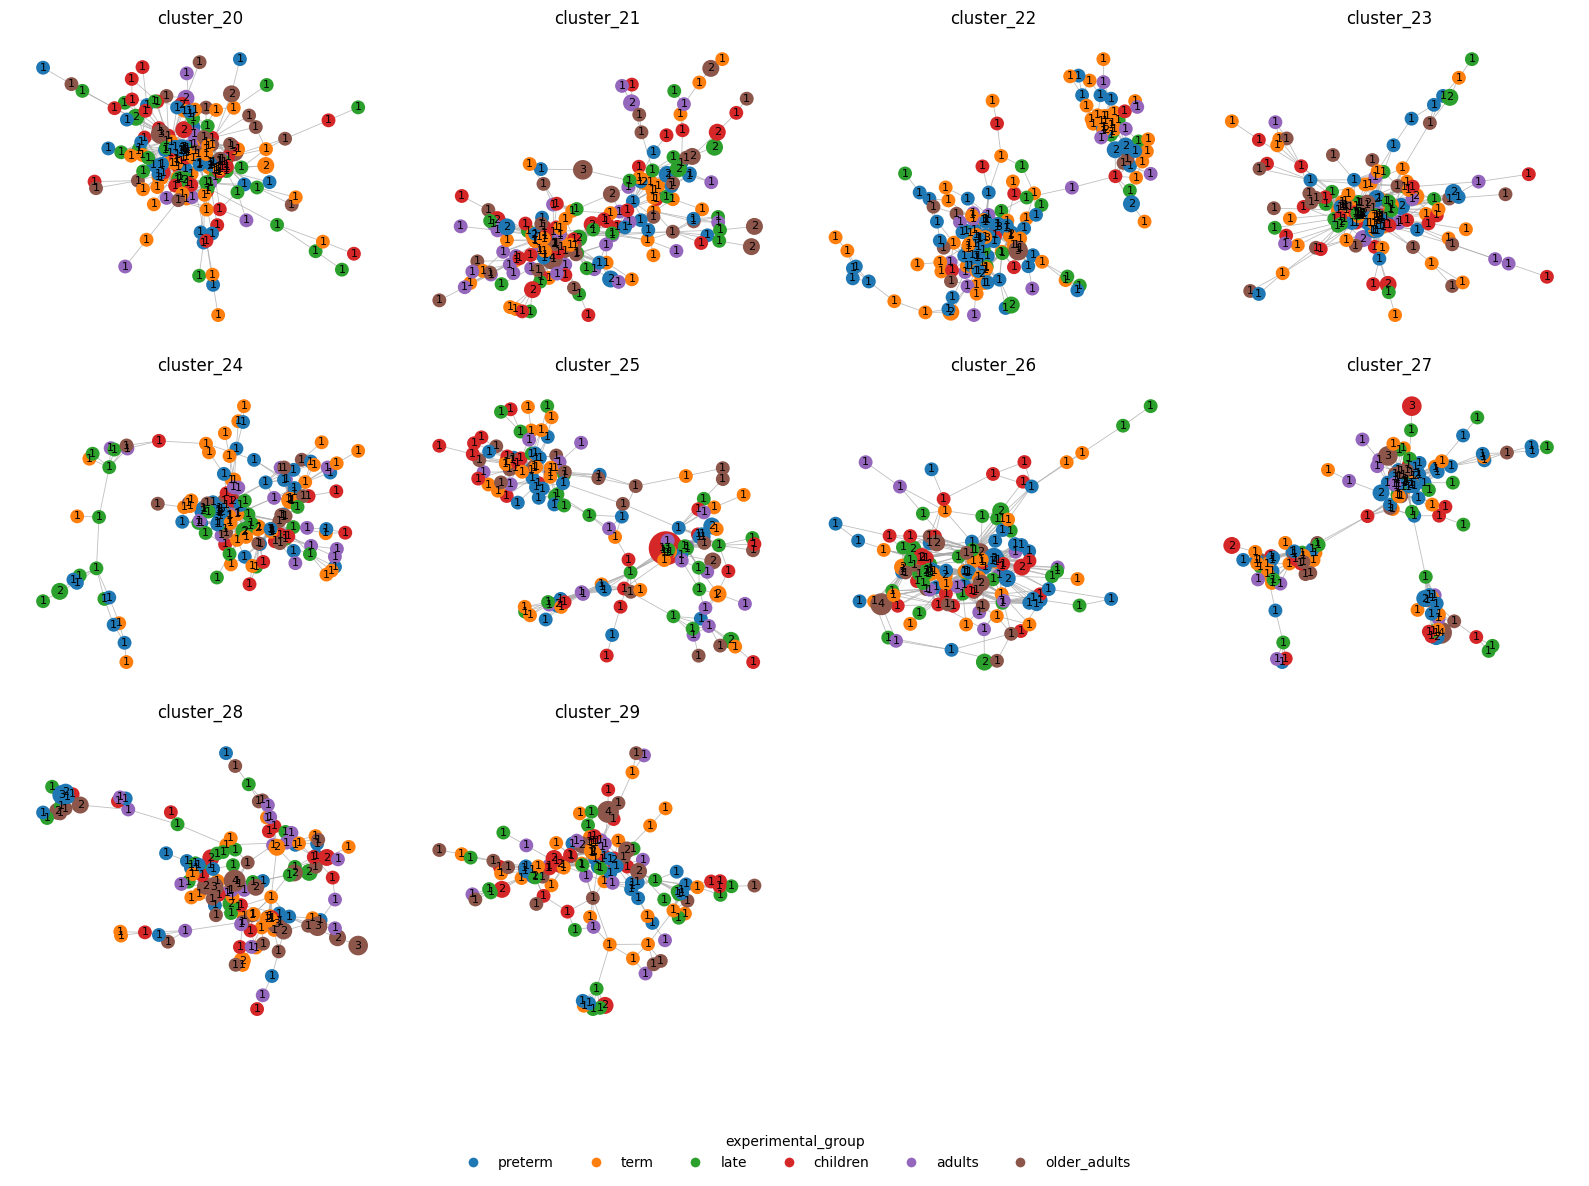

In [63]:
# Рисуем кластеры 20–29; цвет кодирует группу, размер узла — его count.
clusters.plot_cluster(range(20,30), color="experimental_group", label="count", log_scaled=False, size="count", linear_scale=50)

## Проверка устойчивости: downsample 6300 против более глубокого

Повторяем расчет альфа-разнообразия на глубине `DOWNSAMPLE_CHECK`. Самый маленький образец (o7) до нее не дотягивает, поэтому исключаем его явно. Смотрим, сохраняется ли порядок групп по основным метрикам.

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt

clonosets_cd8_deep = clonosets_cd8.merge(
    clonoset_stats_cd8[["sample_id", "reads_func"]], on="sample_id"
).query("reads_func >= @DOWNSAMPLE_CHECK").drop(columns="reads_func").reset_index(drop=True)
print("Глубина проверки:", DOWNSAMPLE_CHECK, "| образцов:", len(clonosets_cd8_deep))

check_filter = clf.Filter(functionality="f", downsample=DOWNSAMPLE_CHECK, by_umi=True, seed=100)
diversity_check = stats.calc_diversity_stats(clonosets_cd8_deep, cl_filter=check_filter, seed=123,
                                             cpu=2, iterations=3, drop_small_samples=False, verbose=True)

Глубина проверки: 8000 | образцов: 26
CalcDiversityStats settings: seed=123, downsample=8000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 26/26 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): c4_nCD8_TRB_1, UCB5_nCD8_TRB_1, a12_nCD8_TRB_1, o4_nCD8_TRB_1, UCB13_nCD8_TRB_1, a6_nCD8_TRB_1, UCB2_nCD8_TRB_1, o3_nCD8_TRB_1, UCB4_nCD8_TRB_1, c5_nCD8_TRB_1, o2_nCD8_TRB_1, UCB3_nCD8_TRB_1, UCB12_nCD8_TRB_1, c2_nCD8_TRB_1, o1_nCD8_TRB_1, a4_nCD8_TRB_1, UCB11_nCD8_TRB_1, c1_nCD8_TRB_1, UCB8_nCD8_TRB_1, o6_nCD8_TRB_1, UCB7_nCD8_TRB_1, a5_nCD8_TRB_1, UCB10_nCD8_TRB_1, UCB6_nCD8_TRB_1, UCB1_nCD8_TRB_2, UCB9_nCD8_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcDiversityStats |##################################################| 26/26 calcultaion(s) processed


In [65]:
# Медианы групп при двух глубинах.
metrics_to_compare = [m for m in ["diversity", "shannon_wiener", "norm_shannon_wiener", "clonality"]
                      if m in diversity_stats.columns]

def per_sample(df, depth):
    out = df.groupby("sample_id")[metrics_to_compare].mean().reset_index()
    out["downsample"] = depth
    return out

depth_comparison = pd.concat([per_sample(diversity_stats, DOWNSAMPLE),
                              per_sample(diversity_check, DOWNSAMPLE_CHECK)]).merge(metadata, on="sample_id")
depth_comparison.groupby(["experimental_group", "downsample"], observed=True)[metrics_to_compare].median().unstack().round(4)

diversity         shannon_wiener          \
downsample              6300    8000           6300    8000   
experimental_group                                            
preterm               5817.0  7253.0         8.6356  8.8483   
term                  6035.0  7575.0         8.6888  8.9117   
late                  5916.5  7395.0         8.6619  8.8792   
children              6001.0  7531.0         8.6791  8.9033   
adults                6148.5  7766.0         8.7128  8.9439   
older_adults          5620.0  6781.0         8.5107  8.6885   

                   norm_shannon_wiener         clonality          
downsample                        6300    8000      6300    8000  
experimental_group                                                
preterm                         0.9962  0.9954    0.0038  0.0046  
term                            0.9981  0.9977    0.0019  0.0023  
late                            0.9973  0.9967    0.0027  0.0033  
children                        0.9978  0.9974    0.0022  0.0026  
adults                          0.9987  0.9985    0.0013  0.0015  
older_adults                    0.9858  0.9849    0.0142  0.0151

In [66]:
# Ранги групп по медиане (1 = самое большое значение): совпадает ли порядок при двух глубинах?
medians = depth_comparison.groupby(["downsample", "experimental_group"], observed=True)[metrics_to_compare].median()
medians.groupby(level="downsample").rank(ascending=False).unstack(level="downsample")

diversity      shannon_wiener      norm_shannon_wiener  \
downsample              6300 8000           6300 8000                6300   
experimental_group                                                          
preterm                  5.0  5.0            5.0  5.0                 5.0   
term                     2.0  2.0            2.0  2.0                 2.0   
late                     4.0  4.0            4.0  4.0                 4.0   
children                 3.0  3.0            3.0  3.0                 3.0   
adults                   1.0  1.0            1.0  1.0                 1.0   
older_adults             6.0  6.0            6.0  6.0                 6.0   

                        clonality       
downsample         8000      6300 8000  
experimental_group                      
preterm             5.0       2.0  2.0  
term                2.0       5.0  5.0  
late                4.0       3.0  3.0  
children            3.0       4.0  4.0  
adults              1.0       6.0  6.0  
older_adults        6.0       1.0  1.0

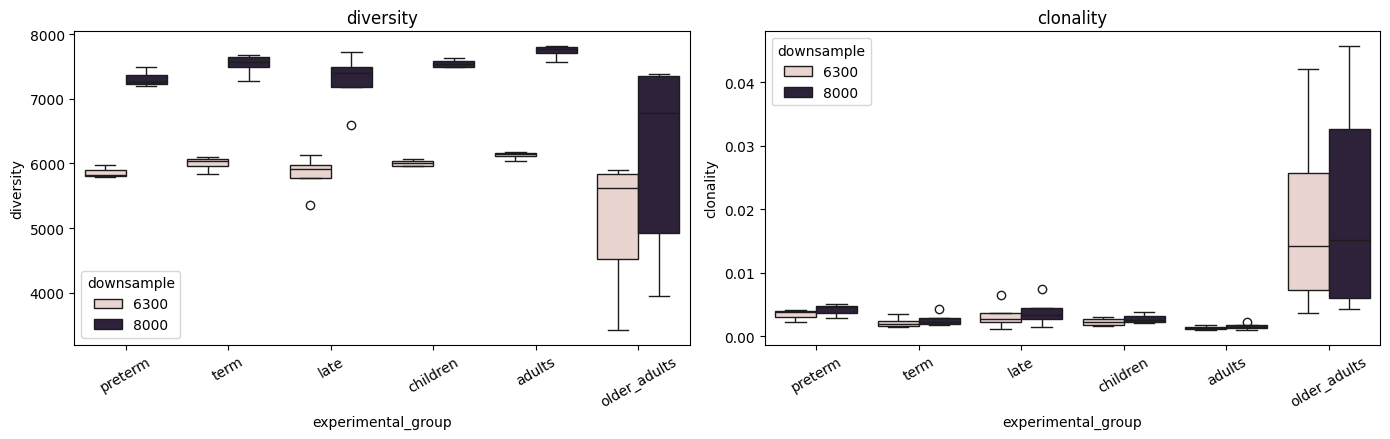

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axes, ["diversity", "clonality"]):
    sns.boxplot(data=depth_comparison, x="experimental_group", y=metric, hue="downsample", ax=ax)
    ax.tick_params(axis="x", rotation=30)
    ax.set_title(metric)
plt.tight_layout()
plt.show()

## Выводы

**Коротко.** Сравнивали 6 возрастных групп в популяции наивных CD8 T-клеток: 3 группы пуповинной крови (preterm, term, late) и 3 группы периферической крови (children, adults, older_adults).
- У preterm CDR3 короче, вставок в 2 раза меньше, больше четверти CDR3 без вставок и convergence выше всех, эффект даже сильнее, чем у CD4.
- Использование V сегментов более равномерное, чем у CD4, с возрастом растут TRBV29-1 и TRBJ2-5, у UCB чаще TRBV12-3.
- Главное отличие от CD4: у older_adults наивные CD8 наименее разнообразные и самые клональные (clonality в 10 раз выше, чем у adults), и этот результат устойчив к изменению глубины.
- У preterm намного больше общих клонотипов между разными детьми (F2 внутри группы 0,038 против 0,0007-0,0011 в периферической крови), особенно у самых недоношенных.
- Главное ограничение: UCB отсортированы только как CD3+CD4-, а периферическая кровь как CD8+CD45RA+CD27+, в группах 3-6 образцов, у пожилых самые маленькие образцы.

**Как читать графики.** На boxplot'ах (свойства CDR3, convergence, разнообразие) по оси X экспериментальные группы, по оси Y значение метрики, одна точка это один образец, линия в ящике это медиана. На распределении длин CDR3 по X длина в аминокислотах, по Y доля клонотипов такой длины. На V/J usage по X сегмент, по Y его доля в репертуаре. На rarefaction по X число наблюдений в подвыборке, по Y сколько разных клонотипов при этом найдено, если кривая выходит на плато значит образец почти насыщен. На тепловой карте F2 каждая клетка это пара образцов, чем краснее тем больше общих клонотипов с учетом их частот. На MDS оси MDS1 и MDS2 условные, у них нет биологического смысла, важно только расстояние: чем ближе точки, тем похожее репертуары. На графе кластеров вершина это клонотип, ребро соединяет клонотипы с одинаковым V и CDR3, отличающимися на 1 аминокислоту.

### Подробно

**Выборка.** В анализ вошли все 27 образцов nCD8: preterm 3, term 6, late 4, children 4, adults 4, older_adults 6. Глубина отличалась примерно в 30 раз (от 6368 до 193529 функциональных наблюдений). Самые маленькие образцы все из older_adults (o7 6368, o2 8056, o3 8941, медиана группы 10720 против 21000-103000 у остальных), поэтому взяли downsample 6300, чтобы не потерять ни одного пожилого. Сортировка тоже разная: все образцы preterm, late и 4 из 6 term отобраны только как CD3+CD4-, то есть это не строго наивные CD8, а образцы периферической крови и 2 term отсортированы как CD3+CD8+CD45RA+CD27+.

**CDR3.** Картина такая же, как у CD4, и даже сильнее. У preterm CDR3 короче (медиана 40,8 нт против 42,5-42,6 у term и late и 43,1-43,3 у детей и взрослых), вставок в 2 раза меньше (3,2 нт против 5,8-7,4), а CDR3 без вставок у preterm 26,8%, у term 7,4%, у late 5,8%, у детей и взрослых около 2,4%. Объяснение то же - у плода на ранних сроках TdT работает слабо.

**V и J сегменты.** В отличие от CD4 тут нет одного явного лидера, использование V более равномерное: TRBV12-3 (7,0%), TRBV5-1 (6,9%), TRBV7-9 (6,3%), TRBV4-1 (6,1%). TRBV12-3 чаще в UCB (около 9,7% у preterm и 9,6% у late против 5,9% у older_adults), TRBV28 выше всего у preterm (6,9% против 3,7-4,7%), а TRBV29-1 растет с возрастом (с 3,4% у preterm до 6,8-6,9% у adults и older_adults), как и у CD4. Среди J лидируют TRBJ2-7 (22,3%) и TRBJ2-1 (19,2%). Как и у CD4, с возрастом растет TRBJ2-5 (с 6,9% до 9,6%) и снижается TRBJ1-2 (с 8,0% до 6,0-6,9%).

**Convergence.** У preterm заметно выше всех (медиана 1,085), у term 1,016, у late 1,011, у детей и взрослых около 1,005. С учетом V гена preterm тоже выше (1,014 против 1,002 и около 1,001). У CD8 эффект сильнее, чем у CD4 (там у preterm было 1,052), что совпадает с большей долей CDR3 без вставок.

**Альфа-разнообразие.** Главное отличие CD8 от CD4 - пожилые. При глубине 6300 медиана diversity максимальная у adults (6149) и минимальная у older_adults (5620). У older_adults clonality 0,014, это примерно в 10 раз больше, чем у adults (0,0013), и медиана доли самого крупного клона 1,2%. Из 6 самых клональных образцов 5 это пожилые: у o4 clonality 0,042 и крупнейший клон занимает 3,1% репертуара, у o7 2,3%, у o3 1,5%, у o2 1,0%. Для наивных клеток это много. Возможно с возрастом наивный пул CD8 уменьшается (на это похожа и маленькая глубина образцов пожилых), а в гейт CD45RA+CD27+ попадают размножившиеся клетки с похожим фенотипом, например клетки памяти. У остальных групп репертуары очень разнообразные, нормированный Шеннон больше 0,996.

**Rarefaction.** Кривые почти у всех растут почти линейно и не выходят на плато. Сильнее всего изгибается кривая o4, самого клонального образца, у него новые клонотипы появляются медленнее.

**Проверка устойчивости.** Пересчитали разнообразие при downsample 8000 (выпадает только o7). Порядок групп полностью сохранился по всем 4 метрикам: по diversity и Шеннону на первом месте adults, на последнем older_adults, по clonality наоборот. В отличие от CD4, тут выводы устойчивые. Но глубина выросла всего в 1,3 раза, потому что следующие маленькие образцы тоже из older_adults и сильнее поднять глубину нельзя без потери этой группы.

**Бета-разнообразие.** Медиана F2 по всем парам 0,0021, это примерно в 2 раза больше, чем у CD4. Средний F2 внутри preterm 0,038, внутри term 0,005, внутри late 0,004, а внутри групп периферической крови 0,0007-0,0011. Самая похожая пара опять UCB1 и UCB5 (F2 = 0,059), это те же самые недоношенные дети (25 и 24 недели), они не родственники. Все 8 самых похожих пар это пары UCB с участием preterm. То есть, как и у CD4, чем раньше срок, тем больше общих (публичных) клонотипов. На MDS образцы UCB лежат компактно в центре, adults тоже держатся вместе, а пожилые разбросаны сильнее всех (o1, o3, o4 далеко от остальных), скорее всего из-за своих крупных клонов, которые делают репертуар более индивидуальным.

**Кластеры.** Самые большие кластеры на TRBV12-3, TRBV27, TRBV7-9 и TRBV5-1, все с TRBJ2-7 и мотивами вида CASSLGG...EQYF. Это короткие последовательности, близкие к зародышевым, поэтому они и собираются в большие кластеры, общую специфичность это не доказывает.

**Сравнение с nCD4 и nTreg.** CDR3 и convergence во всех трех популяциях меняются одинаково, у preterm короче CDR3, меньше вставок и выше convergence, у CD8 этот эффект даже сильнее. А вот с возрастом популяции ведут себя по-разному: у наивных CD8 пожилые самые клональные и наименее разнообразные (и это устойчиво к глубине), у наивных CD4 пожилые наоборот самые разнообразные, а у Treg картина похожа на CD8 (clonality у older_adults 0,011, по данным семинарского ноутбука). Похоже, что наивные CD8 сильнее меняются со старением, чем наивные CD4.

**Ограничения.** В группах мало образцов (3-6), статистика не проверялась, все различия описательные. Образцы UCB отсортированы как CD3+CD4-, а периферическая кровь как CD8+CD45RA+CD27+, поэтому сравнение UCB и периферической крови смешано с разной сортировкой. У пожилых самые маленькие образцы, поэтому глубину нельзя было взять больше. Колонки UMI пустые, считали по reads.